### Stage 0.1 - Setup: imports, paths and the checkpoint settings

In [10]:
# Libraries used in Stage 0 (data build) and Stage 1 (feasibility check)
import pandas as pd
import numpy as np
import os

# ---- Paths: edit RAW_DIR if your original OULAD CSVs are somewhere else ----
RAW_DIR = r"C:\Users\Disha Sharma\Desktop\Paper_1\DATA"      # folder holding the original OULAD CSVs (confirmed by the search cell)
OUT_DIR = r"C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\BBB"      # every output of this notebook is saved here
                                                                # (old whole-course outputs live in RQ4\BBB_wholecourse)
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Which module and presentations we work on ----
MODULE = "BBB"
PRES = ["2013B", "2013J", "2014B"]   # same three presentations as the merged BBB file (2014J was excluded earlier)

# ---- Checkpoints, in days counted from the start of each presentation ----
# 28 = end of week 4, 56 = end of week 8.
# We will count each student's clicks up to these days and see who is still enrolled then.
CUTOFFS = [28, 56]

### Stage 0.2 - Load the students: final result plus registration and unregistration dates

### Stage 0.2a - Locate the original OULAD CSV files on this laptop

In [8]:
import os

# Look for studentInfo.csv in the usual places and print every folder that contains it
home = os.path.expanduser("~")
search_roots = [os.path.join(home, "Desktop"),
                os.path.join(home, "Downloads"),
                os.path.join(home, "Documents")]

needed = ["studentInfo.csv", "studentRegistration.csv", "studentVle.csv", "vle.csv"]  # files this notebook reads

for root in search_roots:
    for folder, _, files in os.walk(root):
        if "studentInfo.csv" in files:
            print("FOUND in:", folder)
            # Check that the other files we need sit in the same folder
            for f in needed:
                print("   ", f, "->", "present" if f in files else "MISSING")

FOUND in: C:\Users\Disha Sharma\Desktop\Paper_1\DATA
    studentInfo.csv -> present
    studentRegistration.csv -> present
    studentVle.csv -> present
    vle.csv -> present


In [13]:
# studentInfo has the final outcome (Withdrawn / Fail / Pass / Distinction) for every student
info = pd.read_csv(os.path.join(RAW_DIR, "studentInfo.csv"))
# studentRegistration has the day each student registered and, if they left, the day they unregistered
reg = pd.read_csv(os.path.join(RAW_DIR, "studentRegistration.csv"))

# Keep only BBB and only the three presentations we use
info = info[(info.code_module == MODULE) & (info.code_presentation.isin(PRES))]
reg = reg[(reg.code_module == MODULE) & (reg.code_presentation.isin(PRES))]

# One row per student with outcome and registration dates
# (date_unregistration is empty for students who never left)
stu = info.merge(
    reg[['code_presentation', 'id_student', 'date_registration', 'date_unregistration']],
    on=['code_presentation', 'id_student'], how='left')

# Sanity checks: these should match the merged BBB file (5617 rows, 1639 Withdrawn, 1376 Fail)
print("students:", len(stu), "(expected 5617)")
print(stu.final_result.value_counts().to_dict())

students: 5617 (expected 5617)
{'Pass': 2105, 'Withdrawn': 1639, 'Fail': 1376, 'Distinction': 497}


### Stage 0.3 - Load the activity-type lookup (tells us which VLE page ids are quizzes, forums, etc.)

In [16]:
# vle.csv maps each VLE page id (id_site) to its activity type, e.g. 'quiz', 'forumng', 'oucontent'
vle = pd.read_csv(os.path.join(RAW_DIR, "vle.csv"))
vle = vle[(vle.code_module == MODULE) & (vle.code_presentation.isin(PRES))][
    ['id_site', 'code_presentation', 'activity_type']]
print("BBB pages:", len(vle), "| activity types:", sorted(vle.activity_type.unique()))

BBB pages: 947 | activity types: ['forumng', 'glossary', 'homepage', 'oucollaborate', 'oucontent', 'ouelluminate', 'quiz', 'resource', 'sharedsubpage', 'subpage', 'url']


### Stage 0.4 - Read the big click file in chunks and keep only BBB rows (slowest cell, a few minutes)

In [19]:
# studentVle.csv is far too big to load at once, so we read it 500,000 rows at a time
# and keep only the BBB rows from the three presentations we use.
parts = []
for i, chunk in enumerate(pd.read_csv(
        os.path.join(RAW_DIR, "studentVle.csv"),
        usecols=['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click'],
        chunksize=500_000)):
    chunk = chunk[(chunk.code_module == MODULE) & (chunk.code_presentation.isin(PRES))]
    if not chunk.empty:
        # Attach the activity type to every click row, using the lookup from the previous cell
        chunk = chunk.merge(vle, on=['id_site', 'code_presentation'], how='left')
        parts.append(chunk[['code_presentation', 'id_student', 'activity_type', 'date', 'sum_click']])
    if i % 5 == 0:
        print("chunks read:", i + 1)     # simple progress indicator

clicks = pd.concat(parts, ignore_index=True)
# 'date' = day of the click counted from the start of the presentation (can be negative = before the start)
print("click rows:", len(clicks), "| date range:", clicks.date.min(), "to", clicks.date.max())
print("clicks with no activity type (should be 0 or tiny):", int(clicks.activity_type.isna().sum()))

chunks read: 1
chunks read: 6
chunks read: 11
chunks read: 16
chunks read: 21
click rows: 1129140 | date range: -23 to 268
clicks with no activity type (should be 0 or tiny): 0


### Stage 0.5 - Build each student's clicks up to every checkpoint, and flag who is still enrolled

In [22]:
keys = ['code_presentation', 'id_student']          # identifies one student in one presentation
feat = stu[keys + ['final_result', 'date_registration', 'date_unregistration']].copy()

for c in CUTOFFS:
    sub = clicks[clicks.date <= c]                  # only clicks that happened up to the checkpoint day

    # Total clicks (all activity types) up to the checkpoint, per student
    tot = (sub.groupby(keys).sum_click.sum()
           .rename(f'total_clicks_d{c}').reset_index())
    # Quiz clicks only, up to the checkpoint, per student
    quiz = (sub[sub.activity_type == 'quiz'].groupby(keys).sum_click.sum()
            .rename(f'quiz_clicks_d{c}').reset_index())

    feat = feat.merge(tot, on=keys, how='left').merge(quiz, on=keys, how='left')
    # A student with no clicks in the window does not appear in the groupby, so they get 0
    feat[[f'total_clicks_d{c}', f'quiz_clicks_d{c}']] = (
        feat[[f'total_clicks_d{c}', f'quiz_clicks_d{c}']].fillna(0))

    # Still enrolled at the checkpoint = registered by then AND not yet unregistered.
    # Missing registration date -> treated as registered early; missing unregistration -> never left.
    feat[f'enrolled_d{c}'] = (
        (feat.date_registration.fillna(-999) <= c) &
        (feat.date_unregistration.isna() | (feat.date_unregistration > c)))

# Save the table so later stages can reload it without re-reading the huge click file
feat.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_features.csv"), index=False)
print(feat.shape)
feat.head()

(5617, 11)


,code_presentation,id_student,final_result,date_registration,date_unregistration,total_clicks_d28,quiz_clicks_d28,enrolled_d28,total_clicks_d56,quiz_clicks_d56,enrolled_d56
0,2013B,23629,Fail,-47.0,NaN,53.0,0.0,True,84.0,18.0,True
1,2013B,25107,Pass,-73.0,NaN,84.0,0.0,True,177.0,23.0,True
2,2013B,27891,Withdrawn,-58.0,153.0,187.0,0.0,True,245.0,13.0,True
3,2013B,29144,Fail,-24.0,NaN,212.0,0.0,True,617.0,28.0,True
4,2013B,31663,Pass,-60.0,NaN,1118.0,0.0,True,2054.0,14.0,True


### Stage 1 - Feasibility tables: can we still reach at-risk students, and does early quiz activity separate outcomes?

In [25]:
def banded(s):
    # Split clicks into bands: exactly 0 clicks, then quartile bands of the students who clicked at all
    nz = s[s > 0]
    qs = sorted({int(round(x)) for x in nz.quantile([.25, .5, .75])} - {0}) if len(nz) else []
    return pd.cut(s, bins=[-1, 0] + qs + [np.inf])

def summarize(df, band_col):
    # For each band: number of students and the % ending as Pass/Distinction, Fail, Withdrawn
    return df.groupby(band_col, observed=True).final_result.agg(
        n='size',
        pct_pass=lambda s: s.isin(['Pass', 'Distinction']).mean() * 100,
        pct_fail=lambda s: (s == 'Fail').mean() * 100,
        pct_withdrawn=lambda s: (s == 'Withdrawn').mean() * 100).round(1)

total_w = (feat.final_result == 'Withdrawn').sum()   # all eventual Withdrawn students in BBB
total_f = (feat.final_result == 'Fail').sum()        # all eventual Fail students in BBB

for c in CUTOFFS:
    e = feat[feat[f'enrolled_d{c}']].copy()          # only students still enrolled at this checkpoint
    print(f"\n=== Checkpoint: day {c} (week {c // 7}) ===")
    print("still enrolled:", len(e), "of", len(feat))
    # How many of the students who later withdrew/failed could still be reached at this point?
    print(f"eventual Withdrawn still enrolled: {(e.final_result == 'Withdrawn').sum()} of {total_w}")
    print(f"eventual Fail still enrolled: {(e.final_result == 'Fail').sum()} of {total_f}")

    # Outcome by early quiz clicks (the main question)
    e['quiz_band'] = banded(e[f'quiz_clicks_d{c}'])
    print("\nOutcome by quiz clicks up to this day:")
    print(summarize(e, 'quiz_band').to_string())

    # Same table with total clicks, to see whether quiz clicks still separate outcomes better
    e['total_band'] = pd.qcut(e[f'total_clicks_d{c}'], 4, duplicates='drop')
    print("\nOutcome by total clicks up to this day (quartiles):")
    print(summarize(e, 'total_band').to_string())


=== Checkpoint: day 28 (week 4) ===
still enrolled: 4643 of 5617
eventual Withdrawn still enrolled: 671 of 1639
eventual Fail still enrolled: 1372 of 1376

Outcome by quiz clicks up to this day:
                n  pct_pass  pct_fail  pct_withdrawn
quiz_band                                           
(-1.0, 0.0]  2818      50.4      33.9           15.8
(0.0, 1.0]    925      61.4      25.2           13.4
(1.0, 3.0]    494      67.6      21.5           10.9
(3.0, inf]    406      68.5      19.5           12.1

Outcome by total clicks up to this day (quartiles):
                    n  pct_pass  pct_fail  pct_withdrawn
total_band                                              
(-0.001, 43.0]   1175      33.4      49.0           17.6
(43.0, 115.0]    1159      53.3      31.3           15.4
(115.0, 233.0]   1149      64.1      22.8           13.1
(233.0, 4668.0]  1160      73.6      14.7           11.6

=== Checkpoint: day 56 (week 8) ===
still enrolled: 4502 of 5617
eventual Withdrawn still 

### Stage 1b - When do the Withdrawn students actually leave? (decides how many a checkpoint can reach)

In [28]:
# Withdrawn students only; date_unregistration = day (from presentation start) they unregistered
w = feat[feat.final_result == 'Withdrawn'].copy()
print("Withdrawn:", len(w), "| with an unregistration date:", int(w.date_unregistration.notna().sum()))

# Buckets for the day of leaving: before the course starts, then successive windows
bins = [-np.inf, -0.5, 14, 28, 56, 112, np.inf]
labels = ['before day 0', 'day 0-14', 'day 15-28', 'day 29-56', 'day 57-112', 'after day 112']
w['left_when'] = pd.cut(w.date_unregistration, bins=bins, labels=labels)

# Count and share of Withdrawn students per bucket, plus the running (cumulative) share
t = w.left_when.value_counts().reindex(labels).to_frame('n')
t['pct'] = (t.n / t.n.sum() * 100).round(1)
t['cumulative_pct'] = t.pct.cumsum().round(1)
print(t.to_string())
print("median day of leaving:", w.date_unregistration.median())

Withdrawn: 1639 | with an unregistration date: 1638
                 n   pct  cumulative_pct
left_when                               
before day 0   618  37.7            37.7
day 0-14       241  14.7            52.4
day 15-28      109   6.7            59.1
day 29-56      142   8.7            67.8
day 57-112     224  13.7            81.5
after day 112  304  18.6           100.1
median day of leaving: 10.5


### Stage 1c - Are early quiz clicks just the first assessment? (tests whether "quiz clicks" is really an assessment proxy)

In [31]:
# Find BBB's assessments and pick the first one per presentation (earliest due date)
assess = pd.read_csv(os.path.join(RAW_DIR, "assessments.csv"))
assess = assess[(assess.code_module == MODULE) & (assess.code_presentation.isin(PRES))]
first = (assess.sort_values(['code_presentation', 'date', 'id_assessment'])
         .groupby('code_presentation').head(1)
         [['id_assessment', 'code_presentation', 'date', 'assessment_type']])
print("First assessment per presentation (date = due day):")
print(first.to_string(index=False))

# Which students submitted that first assessment, and on what day
sa = pd.read_csv(os.path.join(RAW_DIR, "studentAssessment.csv"))
sa1 = sa.merge(first[['id_assessment', 'code_presentation']], on='id_assessment')
sub1 = (sa1[['code_presentation', 'id_student', 'date_submitted']]
        .rename(columns={'date_submitted': 'first_ass_day'}))
chk = feat.merge(sub1, on=keys, how='left')       # 'keys' was defined in Stage 0.5

# Among students still enrolled at day 56: zero quiz clicks vs submitted the first assessment by then
e = chk[chk.enrolled_d56].copy()
e['zero_quiz_d56'] = e.quiz_clicks_d56 == 0
e['submitted_first_by_d56'] = e.first_ass_day.notna() & (e.first_ass_day <= 56)
print("\nCounts:")
print(pd.crosstab(e.zero_quiz_d56, e.submitted_first_by_d56, margins=True))
print("\nRow percentages (share of each quiz group that submitted the first assessment):")
print((pd.crosstab(e.zero_quiz_d56, e.submitted_first_by_d56, normalize='index') * 100).round(1))

First assessment per presentation (date = due day):
 id_assessment code_presentation  date assessment_type
         14984             2013B  19.0             TMA
         14996             2013J  19.0             TMA
         15008             2014B  12.0             TMA

Counts:
submitted_first_by_d56  False  True   All
zero_quiz_d56                            
False                      64  3804  3868
True                      329   305   634
All                       393  4109  4502

Row percentages (share of each quiz group that submitted the first assessment):
submitted_first_by_d56  False  True 
zero_quiz_d56                       
False                     1.7   98.3
True                     51.9   48.1


### Stage 1d - Did the students who unregistered before day 0 re-enrol somewhere else? (tests whether they are really lost)

In [34]:
# Full studentInfo for ALL modules and presentations, so we can see where else these students appear
info_all = pd.read_csv(os.path.join(RAW_DIR, "studentInfo.csv"))

# Students who unregistered before the course started (day < 0) and ended as Withdrawn
pre = feat[(feat.final_result == 'Withdrawn') & (feat.date_unregistration < 0)][keys].copy()
print("Left before day 0:", len(pre))

# Attach every other registration these students have (any module, any presentation)
others = pre.merge(info_all[['id_student', 'code_module', 'code_presentation', 'final_result']],
                   on='id_student', how='left', suffixes=('_x', '_y'))   # _x = BBB row we started from
# Drop the BBB registration we started from, keeping only their OTHER registrations
others = others[~((others.code_module == MODULE) & (others.code_presentation_x == others.code_presentation_y))]

# Students with at least one other registration anywhere
n_other = others[['code_presentation_x', 'id_student']].drop_duplicates().shape[0]
print(f"Appear in another module or presentation: {n_other} of {len(pre)} ({n_other / len(pre) * 100:.1f}%)")

# Students who appear in a LATER BBB presentation (a deferral to the next start date)
same_mod = others[others.code_module == MODULE]
later = same_mod[same_mod.code_presentation_y > same_mod.code_presentation_x]   # strings such as '2013B' < '2013J' sort correctly
n_later = later[['code_presentation_x', 'id_student']].drop_duplicates().shape[0]
print(f"Appear in a later BBB presentation: {n_later} of {len(pre)} ({n_later / len(pre) * 100:.1f}%)")
print("Final result in that later BBB presentation:")
print(later.final_result.value_counts().to_string())

Left before day 0: 618
Appear in another module or presentation: 70 of 618 (11.3%)
Appear in a later BBB presentation: 44 of 618 (7.1%)
Final result in that later BBB presentation:
final_result
Withdrawn      24
Pass           17
Fail            6
Distinction     2


### Stage 2.1 - Clicks by activity type: early period (up to day 28) and action window (days 29 to 56)

In [37]:
EARLY_END = 28      # checkpoint: end of week 4
WIN_END = 56        # end of the action window: end of week 8

def clicks_by_type(df, label):
    # One column per activity type: each student's total clicks of that type in df,
    # named clicks_<type>_<label>. Students with no clicks are missing here and filled with 0 below.
    p = (df.groupby(keys + ['activity_type']).sum_click.sum()
         .unstack('activity_type', fill_value=0))
    p.columns = [f'clicks_{c}_{label}' for c in p.columns]
    return p.reset_index()

early = clicks[clicks.date <= EARLY_END]                                 # up to and including the checkpoint day
window = clicks[(clicks.date > EARLY_END) & (clicks.date <= WIN_END)]    # the action window, after the checkpoint

X = stu[keys].copy()                                                     # one row per student ('keys' from Stage 0.5)
X = X.merge(clicks_by_type(early, 'early'), on=keys, how='left')
X = X.merge(clicks_by_type(window, 'win'), on=keys, how='left')
click_cols = [c for c in X.columns if c.startswith('clicks_')]
X[click_cols] = X[click_cols].fillna(0)                                  # no clicks in the period -> 0
print(len(click_cols), "click columns:", click_cols[:4], "...")

22 click columns: ['clicks_forumng_early', 'clicks_glossary_early', 'clicks_homepage_early', 'clicks_oucollaborate_early'] ...


### Stage 2.2 - First assessment as fixed context: was it submitted by day 28, and what was the score

In [40]:
# 'first' (the first assessment of each presentation) was built in Stage 1c; rebuild the submissions table
sa = pd.read_csv(os.path.join(RAW_DIR, "studentAssessment.csv"))
sa1 = sa.merge(first[['id_assessment', 'code_presentation']], on='id_assessment')   # first assessment only
first_ass = (sa1[['code_presentation', 'id_student', 'date_submitted', 'score']]
             .rename(columns={'date_submitted': 'first_ass_day', 'score': 'first_ass_score'}))
X = X.merge(first_ass, on=keys, how='left')

# Only what was known at the checkpoint counts: submitted on or before day 28
X['first_ass_submitted'] = (X.first_ass_day.notna() & (X.first_ass_day <= EARLY_END)).astype(int)
# Score if submitted by the checkpoint, otherwise -1 (same "not submitted" convention as in RQ1)
X['first_ass_score'] = np.where(X.first_ass_submitted == 1, X.first_ass_score, -1)
X['first_ass_score'] = X.first_ass_score.fillna(-1)
X = X.drop(columns='first_ass_day')
print(X.first_ass_submitted.value_counts().to_dict())

{1: 4141, 0: 1476}


### Stage 2.3 - Add demographics, outcomes and cohort labels, then save the table

In [43]:
demo = ['gender', 'region', 'highest_education', 'imd_band', 'age_band',
        'num_of_prev_attempts', 'studied_credits', 'disability']          # encoded later, at the graph stage
X = X.merge(stu[keys + demo + ['final_result', 'date_registration', 'date_unregistration']],
            on=keys, how='left')

# Still enrolled at each checkpoint (same rule as Stage 0.5)
for c in [28, 56]:
    X[f'enrolled_d{c}'] = ((X.date_registration.fillna(-999) <= c) &
                           (X.date_unregistration.isna() | (X.date_unregistration > c)))

# Cohort labels: order matters, the first matching rule wins
is_w = X.final_result == 'Withdrawn'
X['cohort'] = np.select(
    [is_w & (X.date_unregistration <= 28),                      # Withdrawn, left by day 28
     is_w & X.enrolled_d28 & ~X.enrolled_d56,                   # Withdrawn, left between day 29 and 56
     is_w & X.enrolled_d56,                                     # Withdrawn, still enrolled at day 56
     (X.final_result == 'Fail') & X.enrolled_d56,               # Fail, enrolled at day 56
     X.final_result.isin(['Pass', 'Distinction']) & X.enrolled_d56],   # Success, enrolled at day 56
    ['early_leaver', 'mid_leaver', 'late_leaver', 'fail', 'success'],
    default='other')                                            # e.g. students not enrolled at day 56 for other reasons
print(X.cohort.value_counts().to_string())

# How engagement differs by cohort: median total clicks in the early period and in the window
early_c = [c for c in X.columns if c.endswith('_early')]
win_c = [c for c in X.columns if c.endswith('_win')]
X['total_early'] = X[early_c].sum(axis=1)
X['total_win'] = X[win_c].sum(axis=1)
print(X.groupby('cohort')[['total_early', 'total_win', 'first_ass_submitted']].median().round(1).to_string())

X.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_features.csv"), index=False)
print(X.shape)

cohort
success         2601
fail            1372
early_leaver     968
late_leaver      529
mid_leaver       142
other              5
              total_early  total_win  first_ass_submitted
cohort                                                   
early_leaver          0.0        0.0                  0.0
fail                 63.0       29.0                  1.0
late_leaver          95.0       51.0                  1.0
mid_leaver           79.0        2.5                  1.0
other                 0.0        0.0                  1.0
success             161.0      102.0                  1.0
(5617, 42)


### Stage 2.4 - What do Fail and late-leaver students do differently in weeks 5 to 8? Median clicks per activity type, by cohort

In [46]:
# Keep the three cohorts used for click recourse; early and mid leavers and the 5 'other' students are left out
sub = X[X.cohort.isin(['fail', 'late_leaver', 'success'])].copy()
win_cols = [c for c in X.columns if c.endswith('_win')]                  # window (days 29-56) click columns
short = {c: c.replace('clicks_', '').replace('_win', '') for c in win_cols}   # readable names, e.g. 'quiz'

# Table 1: median clicks per activity type in the window, with each group as a % of Success
med = sub.groupby('cohort')[win_cols].median().T.rename(index=short)
med = med[['fail', 'late_leaver', 'success']]
med['fail_%_of_success'] = (med.fail / med.success.replace(0, np.nan) * 100).round(0)
med['late_leaver_%_of_success'] = (med.late_leaver / med.success.replace(0, np.nan) * 100).round(0)
print("Median clicks per student in days 29-56:")
print(med.to_string())

# Table 2: share of students with at least one click of that type, by cohort
# (medians are 0 for rarely used activities, so this shows whether an activity is used at all)
share = (sub.groupby('cohort')[win_cols].apply(lambda d: (d > 0).mean() * 100)
         .T.rename(index=short).round(1)[['fail', 'late_leaver', 'success']])
print("\n% of students with at least one click of that type in days 29-56:")
print(share.to_string())

Median clicks per student in days 29-56:
cohort         fail  late_leaver  success  fail_%_of_success  late_leaver_%_of_success
forumng         1.0         10.0     40.0                2.0                      25.0
glossary        0.0          0.0      0.0                NaN                       NaN
homepage        7.0         12.0     26.0               27.0                      46.0
oucollaborate   0.0          0.0      0.0                NaN                       NaN
oucontent       0.0          0.0      0.0                NaN                       NaN
ouelluminate    0.0          0.0      0.0                NaN                       NaN
quiz           13.0         14.0     17.0               76.0                      82.0
resource        0.0          0.0      1.0                0.0                       0.0
sharedsubpage   0.0          0.0      0.0                NaN                       NaN
subpage         1.0          2.0      4.0               25.0                      50.0
ur

### Stage 3.1 - Build the graph table: the 4,502 students still enrolled at day 56, encoded and binned

In [49]:
# Students used in the graph: still enrolled at day 56 = Fail + late leavers + Success (4,502)
G = X[X.cohort.isin(['fail', 'late_leaver', 'success'])].copy()
print("graph sample:", len(G), "| cohorts:", G.cohort.value_counts().to_dict())

# ---- Outcome, coded as in RQ1 (Withdrawn here = late leavers only) ----
G['final_result'] = G.final_result.map({'Withdrawn': 0, 'Fail': 1, 'Pass': 2, 'Distinction': 3})

# ---- Demographics: same encodings as the earlier BBB work ----
G['imd_band'] = G.imd_band.fillna(G.imd_band.mode()[0])           # fill missing with the most common band
imd_map = {'0-10%': 0, '10-20': 1, '10-20%': 1, '20-30%': 2, '30-40%': 3, '40-50%': 4,
           '50-60%': 5, '60-70%': 6, '70-80%': 7, '80-90%': 8, '90-100%': 9}   # both spellings of 10-20 handled
G['imd_band'] = G.imd_band.map(imd_map)
G['highest_education'] = G.highest_education.map({
    'No Formal quals': 0, 'Lower Than A Level': 1, 'A Level or Equivalent': 2,
    'HE Qualification': 3, 'Post Graduate Qualification': 4})
G['age_band'] = G.age_band.map({'0-35': 0, '35-55': 1, '55<=': 2})
G['gender'] = G.gender.map({'M': 0, 'F': 1})
G['disability'] = G.disability.map({'N': 0, 'Y': 1})
G['region'] = G.region.astype('category').cat.codes               # nominal, label-encoded as before

# ---- Click and assessment variables need discrete bins for the independence test ----
def bin_variable(s):
    # Mostly-zero variables (more than 50% zeros) cannot be quartile-split: the cut points collapse.
    # For those we use 0 = no clicks, 1 = any clicks. Otherwise quartile bins, as in the earlier work.
    if (s == 0).mean() > 0.5:
        return (s > 0).astype(int)
    return pd.qcut(s, q=4, labels=False, duplicates='drop')

G['total_early'] = pd.qcut(G.total_early, q=4, labels=False, duplicates='drop')   # early engagement composite
G['first_ass_score'] = pd.qcut(G.first_ass_score, q=4, labels=False, duplicates='drop')   # -1 = not submitted, as in RQ1
win7 = ['clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucontent_win', 'clicks_quiz_win',
        'clicks_resource_win', 'clicks_subpage_win', 'clicks_url_win']    # the 7 click types that had edges in the whole-course BBB DAG3
for c in win7:
    G[c] = bin_variable(G[c])

# ---- Final variable set (18) ----
demo = ['gender', 'region', 'highest_education', 'imd_band', 'age_band',
        'num_of_prev_attempts', 'studied_credits', 'disability']
graph_vars = demo + ['total_early', 'first_ass_score'] + win7 + ['final_result']
Gdf = G[graph_vars].copy()

# Check every variable for collapsed bins or missing values before running anything
chk = pd.DataFrame({'n_bins': Gdf.nunique(), 'missing': Gdf.isna().sum(),
                    'pct_in_largest_bin': (Gdf.apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1)})
print(chk.to_string())
Gdf.to_csv(os.path.join(OUT_DIR, f"{MODULE}_graph_table.csv"), index=False)

graph sample: 4502 | cohorts: {'success': 2601, 'fail': 1372, 'late_leaver': 529}
                      n_bins  missing  pct_in_largest_bin
gender                     2        0                88.4
region                    13        0                12.2
highest_education          5        0                43.8
imd_band                   9      535                15.6
age_band                   3        0                65.7
num_of_prev_attempts       7        0                83.4
studied_credits           21        0                65.5
disability                 2        0                90.3
total_early                4        0                25.5
first_ass_score            4        0                29.0
clicks_forumng_win         3        0                51.1
clicks_homepage_win        4        0                25.7
clicks_oucontent_win       2        0                84.8
clicks_quiz_win            4        0                27.9
clicks_resource_win        3        0           

### Stage 3.1b - Fix imd_band, collapse the two high-cardinality immutables, rebuild the graph table

In [52]:
# ---- imd_band: parse the leading number of the raw label, so spelling variants cannot break the mapping ----
raw_imd = X.loc[G.index, 'imd_band']                       # X still holds the raw text labels
print("raw imd_band labels:\n", raw_imd.value_counts(dropna=False).to_string())
lower = raw_imd.str.extract(r'^(\d+)')[0].astype(float)    # '0-10%' -> 0, '10-20' -> 10, ... '90-100%' -> 90
imd = (lower // 10)                                        # deprivation band 0..9
G['imd_band'] = imd.fillna(imd.mode()[0]).astype(int)      # the few truly missing labels get the most common band

# ---- gender: show the raw counts to check the 88.4% in one bin ----
print("\nraw gender counts:\n", X.loc[G.index, 'gender'].value_counts().to_string())

# ---- Collapse studied_credits and num_of_prev_attempts to few categories (fewer sparse tables for the test) ----
G['studied_credits'] = pd.cut(G.studied_credits, bins=[0, 60, 90, np.inf], labels=False)   # 0: <=60, 1: 61-90, 2: >90
G['num_of_prev_attempts'] = G.num_of_prev_attempts.clip(upper=2)                              # 0, 1, 2 or more

# ---- Rebuild the graph table and re-run the check ----
Gdf = G[graph_vars].copy()
chk = pd.DataFrame({'n_bins': Gdf.nunique(), 'missing': Gdf.isna().sum(),
                    'pct_in_largest_bin': (Gdf.apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1)})
print("\n", chk.to_string())
Gdf.to_csv(os.path.join(OUT_DIR, f"{MODULE}_graph_table.csv"), index=False)

raw imd_band labels:
 imd_band
0-10%      577
20-30%     549
Oct-20     535
30-40%     515
40-50%     481
50-60%     424
60-70%     394
70-80%     377
80-90%     337
90-100%    270
NaN         43

raw gender counts:
 gender
F    3980
M     522

                       n_bins  missing  pct_in_largest_bin
gender                     2        0                88.4
region                    13        0                12.2
highest_education          5        0                43.8
imd_band                   9        0                25.7
age_band                   3        0                65.7
num_of_prev_attempts       3        0                83.4
studied_credits            3        0                65.5
disability                 2        0                90.3
total_early                4        0                25.5
first_ass_score            4        0                29.0
clicks_forumng_win         3        0                51.1
clicks_homepage_win        4        0                25.7


### Stage 3.1c - Fix imd_band properly ('Oct-20' is the 10-20% band) and rebuild the graph table

In [61]:
raw_imd = X.loc[G.index, 'imd_band']        # raw text labels for the 4,502 students

# 'Oct-20' is how the raw file stores the 10-20% band (a spreadsheet turned '10-20' into a date-like text)
imd_map = {'0-10%': 0, 'Oct-20': 1, '10-20': 1, '10-20%': 1, '20-30%': 2, '30-40%': 3,
           '40-50%': 4, '50-60%': 5, '60-70%': 6, '70-80%': 7, '80-90%': 8, '90-100%': 9}
imd = raw_imd.map(imd_map)

# Only the 43 truly missing labels should be unmapped now
print("unmapped labels:", raw_imd[imd.isna()].value_counts(dropna=False).to_dict())
G['imd_band'] = imd.fillna(imd.mode()[0]).astype(int)      # the 43 missing get the most common band, as before

# Rebuild the graph table and re-check: imd_band should now show 10 bins and no oversized band
Gdf = G[graph_vars].copy()
chk = pd.DataFrame({'n_bins': Gdf.nunique(), 'missing': Gdf.isna().sum(),
                    'pct_in_largest_bin': (Gdf.apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1)})
print(chk.loc[['imd_band']].to_string())
Gdf.to_csv(os.path.join(OUT_DIR, f"{MODULE}_graph_table.csv"), index=False)

unmapped labels: {nan: 43}
          n_bins  missing  pct_in_largest_bin
imd_band      10        0                13.8


### Stage 3.1d - Zero-aware binning: 0 = no activity, levels 1-3 = equal-sized bands among students who were active

In [79]:
def bin_zero_aware(s, n_levels=3):
    # Level 0 = no activity at all; levels 1..n_levels = equal-count bands among students with some activity.
    # Keeping "none" as its own level preserves the participation effect that quartile bins blur together.
    out = pd.Series(0, index=s.index, dtype=int)
    active = s > 0
    if active.sum() > 0:
        try:
            bands = pd.qcut(s[active], q=n_levels, labels=False, duplicates='drop')
            out[active] = bands.astype(int) + 1
        except ValueError:
            out[active] = 1                      # too few distinct values to split: just 'some activity'
    return out

# Window click types: re-bin from the RAW counts still stored in X (G holds the earlier quartile versions)
for c in win7:
    G[c] = bin_zero_aware(X.loc[G.index, c])

# First assessment: level 0 = not submitted by day 28; levels 1-3 = terciles of the score among submitters
raw_fa = X.loc[G.index, 'first_ass_score']
fa = pd.Series(0, index=G.index, dtype=int)
submitted = raw_fa >= 0
fa[submitted] = pd.qcut(raw_fa[submitted], q=3, labels=False, duplicates='drop').astype(int) + 1
G['first_ass_score'] = fa
# total_early stays as quartile bins: almost every student has some early activity, so 'none' is rare

# Rebuild the graph table and show the new variable check, including the share of students at level 0
Gdf = G[graph_vars].copy()
chk = pd.DataFrame({'n_levels': Gdf.nunique(),
                    'pct_level_0': (Gdf == 0).mean().mul(100).round(1),
                    'pct_in_largest_level': (Gdf.apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1)})
print(chk.loc[['total_early', 'first_ass_score'] + win7].to_string())
Gdf.to_csv(os.path.join(OUT_DIR, f"{MODULE}_graph_table.csv"), index=False)

                      n_levels  pct_level_0  pct_in_largest_level
total_early                  4         25.5                  25.5
first_ass_score              4         10.6                  31.1
clicks_forumng_win           4         26.3                  26.3
clicks_homepage_win          4         11.5                  30.6
clicks_oucontent_win         4         84.8                  84.8
clicks_quiz_win              4         17.7                  30.9
clicks_resource_win          4         47.0                  47.0
clicks_subpage_win           4         30.5                  30.5
clicks_url_win               4         43.2                  43.2


### Stage 3.2 - Run PC (same method as the whole-course BBB graph) with time-ordering rules, then read every edge

In [95]:
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.cit import chisq, gsq
from causallearn.graph.GraphNode import GraphNode
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge

node_names = list(Gdf.columns)               # the 18 variables from Stage 3.1b
data = Gdf.values.astype(int)                # integer category codes for the G-square test
nodes = [GraphNode(name) for name in node_names]
node_map = {name: node for name, node in zip(node_names, nodes)}

# Time order: earlier tiers can cause later tiers, never the reverse
tiers = {0: demo,                                   # registration-time background information
         1: ['total_early', 'first_ass_score'],     # early engagement and first assessment, up to day 28
         2: win7,                                   # clicks in the action window, days 29 to 56
         3: ['final_result']}                       # outcome
tier_of = {n: t for t, ns in tiers.items() for n in ns}

bk = BackgroundKnowledge()
# Rule A (old rules 1, 4, 5): a later tier cannot cause an earlier tier
for t_late, ns_late in tiers.items():
    for t_early, ns_early in tiers.items():
        if t_late > t_early:
            for late in ns_late:
                for early in ns_early:
                    bk.add_forbidden_by_node(node_map[late], node_map[early])
# Rule B (old rule 2): nothing can cause gender (exogenous root)
for n in node_names:
    if n != 'gender':
        bk.add_forbidden_by_node(node_map[n], node_map['gender'])
# Rule C (old rule 6): the first assessment score cannot cause early engagement
bk.add_forbidden_by_node(node_map['first_ass_score'], node_map['total_early'])

cg = pc(data, alpha=0.05, indep_test=gsq, background_knowledge=bk, node_names=node_names)
print("Number of edges:", cg.G.get_num_edges())

# Read every edge from its endpoints (not from the picture, which can be visually ambiguous)
directed, undirected = [], []
for e in cg.G.get_graph_edges():
    a, b = e.get_node1().get_name(), e.get_node2().get_name()
    ea, eb = e.get_endpoint1().name, e.get_endpoint2().name
    if ea == 'TAIL' and eb == 'ARROW':
        directed.append((a, b))
    elif ea == 'ARROW' and eb == 'TAIL':
        directed.append((b, a))
    else:
        undirected.append((a, b, ea, eb))
print("directed:", len(directed), "| undirected/other:", len(undirected))

# Check that every rule was respected
bad = [(a, b) for a, b in directed if tier_of[a] > tier_of[b] or b == 'gender']
print("rule violations:", bad)

# Edge list in the same text format as the earlier lists
for a, b in directed:
    print(f"{a} [TAIL] -- [ARROW] {b}")
for a, b, ea, eb in undirected:
    print(f"{a} [{ea}] -- [{eb}] {b}")

# Which variables reach the outcome directly, and which are not connected to anything
print("\ndirect parents of final_result:", [a for a, b in directed if b == 'final_result'])
connected = {x for a, b in directed for x in (a, b)} | {x for a, b, _, _ in undirected for x in (a, b)}
print("isolated variables:", [n for n in node_names if n not in connected])

  0%|          | 0/18 [00:00<?, ?it/s]

Number of edges: 27
directed: 24 | undirected/other: 3
rule violations: []
gender [TAIL] -- [ARROW] age_band
region [TAIL] -- [ARROW] first_ass_score
highest_education [TAIL] -- [ARROW] age_band
highest_education [TAIL] -- [ARROW] final_result
total_early [TAIL] -- [ARROW] first_ass_score
total_early [TAIL] -- [ARROW] clicks_forumng_win
total_early [TAIL] -- [ARROW] clicks_homepage_win
first_ass_score [TAIL] -- [ARROW] clicks_homepage_win
first_ass_score [TAIL] -- [ARROW] clicks_quiz_win
first_ass_score [TAIL] -- [ARROW] final_result
clicks_forumng_win [TAIL] -- [ARROW] clicks_homepage_win
clicks_forumng_win [TAIL] -- [ARROW] clicks_subpage_win
clicks_url_win [TAIL] -- [ARROW] clicks_forumng_win
clicks_homepage_win [TAIL] -- [ARROW] clicks_quiz_win
clicks_resource_win [TAIL] -- [ARROW] clicks_homepage_win
clicks_homepage_win [TAIL] -- [ARROW] clicks_subpage_win
clicks_url_win [TAIL] -- [ARROW] clicks_homepage_win
clicks_homepage_win [TAIL] -- [ARROW] final_result
clicks_subpage_win [TA

### Stage 3.3 - Draw the graph: one colour per time tier, tiers stacked top to bottom, edges touching final_result in green

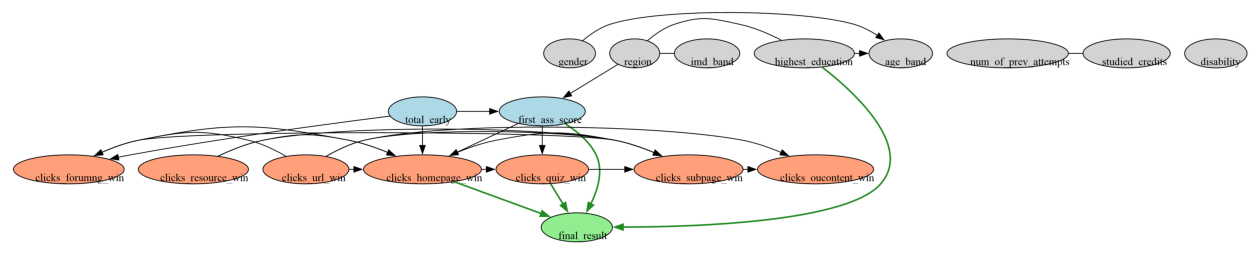

In [98]:
import io, pydot
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from causallearn.utils.GraphUtils import GraphUtils

dot_path = r"C:\Users\Disha Sharma\.conda\envs\analytics\Library\bin\dot.exe"   # full path, as before
pyd = GraphUtils.to_pydot(cg.G, labels=node_names)

def to_idx(x):
    # pydot may return node references as int or as quoted text; convert both to a plain int index
    return int(str(x).strip('"'))

tier_color = {0: 'lightgray', 1: 'lightblue', 2: 'lightsalmon', 3: 'lightgreen'}
for node in pyd.get_nodes():
    s = str(node.get_name()).strip('"')
    if not s.isdigit():
        continue                                   # skip pydot's default settings entries
    label = node_names[int(s)]
    node.set_style('filled'); node.set_fillcolor(tier_color[tier_of[label]])
    node.set_fontsize('10'); node.set_fixedsize('false'); node.set_margin('0.15,0.08')

# Edges touching the outcome in green so the direct drivers stand out at a glance
for edge in pyd.get_edges():
    src = node_names[to_idx(edge.get_source())]
    dst = node_names[to_idx(edge.get_destination())]
    if 'final_result' in (src, dst):
        edge.set_color('forestgreen'); edge.set_penwidth('2')

# Stack the tiers: every variable of one tier on the same row
for t, names in tiers.items():
    sg = pydot.Subgraph(rank='same')
    for n in names:
        sg.add_node(pydot.Node(str(node_names.index(n))))
    pyd.add_subgraph(sg)

png_data = pyd.create_png(prog=dot_path)           # not pyd.write_png(), which calls plain 'dot' and fails
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_PC_graph.png"), "wb") as f:
    f.write(png_data)

plt.figure(figsize=(16, 12))
plt.imshow(mpimg.imread(io.BytesIO(png_data)))
plt.axis('off')
plt.show()

### Stage 3.4 - Freeze the DAG: save the edge list, then list every variable's role, whether it reaches the outcome, and its adjustment set

In [68]:
import networkx as nx

# Build the DAG from the directed edges only. The two undirected pairs (num_of_prev_attempts--studied_credits and
# resource--subpage) have no usable direction, so they are left out, as in the earlier RQ2 and RQ3 work.
dag = nx.DiGraph()
dag.add_nodes_from(node_names)
dag.add_edges_from(directed)
assert nx.is_directed_acyclic_graph(dag), "graph has a cycle"

# Save the edge lists so later stages reload exactly this graph
pd.DataFrame(directed, columns=['from', 'to']).to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_dag_edges.csv"), index=False)
pd.DataFrame([(a, b) for a, b, _, _ in undirected], columns=['a', 'b']).to_csv(
    os.path.join(OUT_DIR, f"{MODULE}_checkpoint_dag_undirected.csv"), index=False)

# One row per variable: its tier and role, whether it can affect the outcome, and what must be adjusted for
role = {0: 'immutable context', 1: 'fixed context (known at checkpoint)', 2: 'lever (action window)', 3: 'outcome'}
rows = []
for n in node_names:
    if n == 'final_result':
        continue
    rows.append({'variable': n,
                 'role': role[tier_of[n]],
                 'path_to_outcome': nx.has_path(dag, n, 'final_result'),       # any directed route to final_result
                 'direct_to_outcome': dag.has_edge(n, 'final_result'),         # an edge straight into final_result
                 'adjustment_set': sorted(dag.predecessors(n))})               # direct parents = backdoor adjustment set here
roles = pd.DataFrame(rows)
print(roles.to_string(index=False))
roles.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_roles_adjustment_sets.csv"), index=False)

# Levers with a path to the outcome are the treatments for effect estimation (Stage 4)
levers = roles[(roles.role == 'lever (action window)') & roles.path_to_outcome].variable.tolist()
print("\nlever treatments:", levers)
print("levers with no path to the outcome (dropped):", [n for n in win7 if n not in levers])

            variable                                role  path_to_outcome  direct_to_outcome                                                                                              adjustment_set
              gender                   immutable context             True              False                                                                                                          []
              region                   immutable context             True              False                                                                       [gender, highest_education, imd_band]
   highest_education                   immutable context             True               True                                                                                                          []
            imd_band                   immutable context             True              False                                                                                                        

### Stage 3.5 - Sensitivity: the same PC run with alpha = 0.10, to see whether sparse variables (content pages) gain edges

In [110]:
# Same data, same background-knowledge rules (bk), only the significance level changes: 0.10 instead of 0.05.
# A looser level lets weak but real links in sparse variables (85% zeros for content pages) survive the independence tests.
cg10 = pc(data, alpha=0.10, indep_test=gsq, background_knowledge=bk,
          node_names=node_names, show_progress=False)

def edge_sets(cg_):
    # Split the edges of a PC result into directed (cause, effect) pairs and undirected pairs
    d, u = set(), set()
    for e in cg_.G.get_graph_edges():
        a, b = e.get_node1().get_name(), e.get_node2().get_name()
        ea, eb = e.get_endpoint1().name, e.get_endpoint2().name
        if ea == 'TAIL' and eb == 'ARROW':
            d.add((a, b))
        elif ea == 'ARROW' and eb == 'TAIL':
            d.add((b, a))
        else:
            u.add(tuple(sorted((a, b))))
    return d, u

d05, u05 = set(directed), {tuple(sorted((a, b))) for a, b, _, _ in undirected}     # the alpha = 0.05 result from Stage 3.2
d10, u10 = edge_sets(cg10)

print("edges at 0.05:", len(d05) + len(u05), "| at 0.10:", len(d10) + len(u10))
print("directed edges gained at 0.10:", sorted(d10 - d05))
print("directed edges lost at 0.10:", sorted(d05 - d10))
print("direct parents of final_result at 0.10:", sorted(a for a, b in d10 if b == 'final_result'))
print("edges touching content pages at 0.10:", sorted(e for e in (d10 | u10) if 'clicks_oucontent_win' in e))

edges at 0.05: 27 | at 0.10: 31
directed edges gained at 0.10: [('clicks_forumng_win', 'clicks_url_win'), ('clicks_homepage_win', 'clicks_url_win'), ('clicks_oucontent_win', 'clicks_subpage_win'), ('clicks_oucontent_win', 'clicks_url_win'), ('clicks_resource_win', 'clicks_url_win'), ('clicks_subpage_win', 'clicks_quiz_win'), ('imd_band', 'final_result'), ('total_early', 'clicks_resource_win'), ('total_early', 'clicks_subpage_win')]
directed edges lost at 0.10: [('clicks_quiz_win', 'clicks_subpage_win'), ('clicks_subpage_win', 'clicks_oucontent_win'), ('clicks_url_win', 'clicks_forumng_win'), ('clicks_url_win', 'clicks_homepage_win'), ('clicks_url_win', 'clicks_oucontent_win')]
direct parents of final_result at 0.10: ['clicks_homepage_win', 'clicks_quiz_win', 'first_ass_score', 'highest_education', 'imd_band']
edges touching content pages at 0.10: [('clicks_oucontent_win', 'clicks_subpage_win'), ('clicks_oucontent_win', 'clicks_url_win')]


### Stage 3.4 (revised) - Freeze the DAG: PC edges plus early clicks and first assessment as parents of every window click; roles and adjustment sets

In [100]:
import networkx as nx

dag = nx.DiGraph()
dag.add_nodes_from(node_names)
dag.add_edges_from(directed)                  # edges found by PC (undirected pairs left out, as in the earlier work)

# Domain-knowledge addition: what a student did before the window can influence what they do in it.
# Add early clicks and first assessment as parents of every window click type if PC did not already link them.
extra = [(src, c) for c in win7 for src in ['total_early', 'first_ass_score'] if not dag.has_edge(src, c)]
dag.add_edges_from(extra)
assert nx.is_directed_acyclic_graph(dag), "graph has a cycle"
print("edges from PC:", len(directed), "| added by us:", len(extra))
print("added edges:", extra)

# Save the final edge list (with a column showing where each edge came from)
edges_out = pd.DataFrame([(a, b, 'PC') for a, b in directed] + [(a, b, 'added') for a, b in extra],
                         columns=['from', 'to', 'source'])
edges_out.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_dag_edges.csv"), index=False)

# Roles and adjustment sets (direct parents) for every variable, now including the added parents
role = {0: 'immutable context', 1: 'fixed context (known at checkpoint)', 2: 'lever (action window)', 3: 'outcome'}
rows = []
for n in node_names:
    if n == 'final_result':
        continue
    rows.append({'variable': n, 'role': role[tier_of[n]],
                 'path_to_outcome': nx.has_path(dag, n, 'final_result'),
                 'direct_to_outcome': dag.has_edge(n, 'final_result'),
                 'adjustment_set': sorted(dag.predecessors(n))})
roles = pd.DataFrame(rows)
roles.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_roles_adjustment_sets.csv"), index=False)
levers = roles[(roles.role == 'lever (action window)') & roles.path_to_outcome].variable.tolist()
print("lever treatments:", levers)
print("levers with no path to the outcome (dropped):", [n for n in win7 if n not in levers])
print(roles[['variable', 'path_to_outcome', 'direct_to_outcome', 'adjustment_set']].to_string(index=False))

edges from PC: 24 | added by us: 10
added edges: [('first_ass_score', 'clicks_forumng_win'), ('total_early', 'clicks_oucontent_win'), ('first_ass_score', 'clicks_oucontent_win'), ('total_early', 'clicks_quiz_win'), ('total_early', 'clicks_resource_win'), ('first_ass_score', 'clicks_resource_win'), ('total_early', 'clicks_subpage_win'), ('first_ass_score', 'clicks_subpage_win'), ('total_early', 'clicks_url_win'), ('first_ass_score', 'clicks_url_win')]
lever treatments: ['clicks_forumng_win', 'clicks_homepage_win', 'clicks_quiz_win', 'clicks_resource_win', 'clicks_url_win']
levers with no path to the outcome (dropped): ['clicks_oucontent_win', 'clicks_subpage_win']
            variable  path_to_outcome  direct_to_outcome                                                                                                                adjustment_set
              gender            False              False                                                                                         

### Stage 4.1 - Effect of each variable on final_result (DoWhy, linear backdoor estimate with 95% CI, placebo and random-common-cause refutation)

In [118]:
import logging, warnings
from dowhy import CausalModel
warnings.filterwarnings('ignore')
logging.getLogger('dowhy').setLevel(logging.ERROR)          # keep the output readable

# Treatments: every variable with a directed path to the outcome (12 in total)
treatments = roles[roles.path_to_outcome].variable.tolist()
print(len(treatments), "treatments:", treatments)

def estimate_one(t, adj):
    # One treatment at a time, adjusting only for its parents in the frozen DAG (the adjustment set)
    model = CausalModel(data=Gdf, treatment=t, outcome='final_result',
                        common_causes=adj if adj else None)           # no graph string, so no DOT problems
    ident = model.identify_effect(proceed_when_unidentifiable=True)
    est = model.estimate_effect(ident, method_name="backdoor.linear_regression",
                                confidence_intervals=True)
    ci = np.array(est.get_confidence_intervals(), dtype=float).flatten()
    out = {'ATE': float(est.value), 'CI_low': float(ci[0]), 'CI_high': float(ci[1])}

    # Refutation 1: replace the treatment with a random permutation; the effect should collapse to about 0
    try:
        r = model.refute_estimate(ident, est, method_name="placebo_treatment_refuter",
                                  placebo_type="permute", num_simulations=50)
        out['placebo_effect'] = float(r.new_effect)
        out['placebo_p'] = r.refutation_result.get('p_value') if isinstance(r.refutation_result, dict) else None
    except Exception as e:
        out['placebo_effect'], out['placebo_p'] = None, str(e)[:40]
    # Refutation 2: add a random extra confounder; the effect should barely move
    try:
        r = model.refute_estimate(ident, est, method_name="random_common_cause", num_simulations=50)
        out['random_cc_effect'] = float(r.new_effect)
    except Exception as e:
        out['random_cc_effect'] = None
    return out

results = []            # reset before every rerun, otherwise a rerun appends duplicate rows
for t in treatments:
    adj = roles.loc[roles.variable == t, 'adjustment_set'].iloc[0]
    row = {'variable': t, 'role': roles.loc[roles.variable == t, 'role'].iloc[0],
           'adjustment_set': ', '.join(adj) if adj else '(none)'}
    row.update(estimate_one(t, adj))
    row['significant'] = (row['CI_low'] > 0) or (row['CI_high'] < 0)   # confidence interval excludes zero
    results.append(row)
    print("done:", t)

ate = pd.DataFrame(results)
cols = ['variable', 'role', 'ATE', 'CI_low', 'CI_high', 'significant',
        'placebo_effect', 'placebo_p', 'random_cc_effect', 'adjustment_set']
print(ate[cols].round(3).to_string(index=False))
ate.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_ATE.csv"), index=False)

11 treatments: ['region', 'highest_education', 'total_early', 'first_ass_score', 'clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucontent_win', 'clicks_quiz_win', 'clicks_resource_win', 'clicks_subpage_win', 'clicks_url_win']
done: region
done: highest_education
done: total_early
done: first_ass_score
done: clicks_forumng_win
done: clicks_homepage_win
done: clicks_oucontent_win
done: clicks_quiz_win
done: clicks_resource_win
done: clicks_subpage_win
done: clicks_url_win
            variable                                role   ATE  CI_low  CI_high  significant  placebo_effect  placebo_p  random_cc_effect                                                                                                              adjustment_set
              region                   immutable context 0.007   0.001    0.013         True          -0.000      0.467             0.007                                                                                                                      (n

### Stage 4.2 - Robustness: lever effects under heavier adjustment, and a step-by-step breakdown of why the quiz effect shrank

In [74]:
import statsmodels.api as sm

# Variables known before the action window opens: safe to adjust for, whatever the graph says
context = ['total_early', 'first_ass_score']
background = ['gender', 'highest_education', 'imd_band', 'age_band',
              'num_of_prev_attempts', 'studied_credits', 'disability']
reg_dummies = pd.get_dummies(Gdf['region'], prefix='reg', drop_first=True).astype(float)  # region is nominal: use dummies

def ols_effect(t, adj, with_region=False):
    # Same linear model DoWhy uses for the backdoor estimate: outcome ~ treatment + adjustment variables
    parts = [Gdf[[t] + adj].astype(float)]
    if with_region:
        parts.append(reg_dummies)
    X_ = sm.add_constant(pd.concat(parts, axis=1))
    m = sm.OLS(Gdf['final_result'].astype(float), X_).fit()
    lo, hi = m.conf_int().loc[t]
    return round(m.params[t], 3), round(lo, 3), round(hi, 3)

# ---- Table 1: each lever under three adjustment levels ----
rows = []                                  # reset before every rerun
for t in levers:
    graph_adj = roles.loc[roles.variable == t, 'adjustment_set'].iloc[0]          # from the DAG (Stage 4.1)
    plus_ctx = sorted(set(graph_adj) | set(context))                               # + early engagement, first assessment
    plus_all = sorted(set(plus_ctx) | set(background))                             # + background (region as dummies)
    rows.append({'lever': t,
                 'graph_set': ols_effect(t, graph_adj),
                 '+context': ols_effect(t, plus_ctx),
                 '+context+background': ols_effect(t, plus_all, with_region=True)})
print("Lever effects (ATE, CI low, CI high):")
print(pd.DataFrame(rows).to_string(index=False))

# ---- Table 2: why did the quiz effect shrink? Add adjustments one step at a time ----
steps = [('nothing', []),
         ('+ early clicks', ['total_early']),
         ('+ first assessment', ['total_early', 'first_ass_score']),
         ('+ homepage and subpage clicks (the graph set)',
          ['total_early', 'first_ass_score', 'clicks_homepage_win', 'clicks_subpage_win']),
         ('+ background', ['total_early', 'first_ass_score', 'clicks_homepage_win', 'clicks_subpage_win'] + background)]
q = []
for label, adj in steps:
    q.append({'adjusted for': label, 'quiz effect (ATE, CI low, CI high)': ols_effect('clicks_quiz_win', adj, with_region=('background' in label))})
print("\nQuiz effect, step by step:")
print(pd.DataFrame(q).to_string(index=False))

Lever effects (ATE, CI low, CI high):
              lever             graph_set              +context    +context+background
 clicks_forumng_win  (0.157, 0.12, 0.194) (0.132, 0.096, 0.167)  (0.123, 0.088, 0.158)
clicks_homepage_win (0.154, 0.117, 0.191) (0.154, 0.117, 0.191)  (0.149, 0.113, 0.186)
    clicks_quiz_win  (0.06, 0.037, 0.083) (0.061, 0.038, 0.083)  (0.055, 0.032, 0.077)
clicks_resource_win (0.118, 0.088, 0.148) (0.036, 0.007, 0.065) (0.027, -0.002, 0.056)
 clicks_subpage_win (0.194, 0.164, 0.224) (0.093, 0.063, 0.123)  (0.081, 0.051, 0.111)
     clicks_url_win  (0.07, 0.037, 0.103) (0.061, 0.029, 0.092)   (0.06, 0.029, 0.091)

Quiz effect, step by step:
                                 adjusted for quiz effect (ATE, CI low, CI high)
                                      nothing               (0.18, 0.159, 0.202)
                               + early clicks               (0.127, 0.105, 0.15)
                           + first assessment               (0.102, 0.08, 0.123)
+

In [76]:
# ---- (a) Same simple model (outcome ~ quiz bin) on three different samples ----
base = feat.copy()                                              # all 5,617 students, quiz clicks up to day 56 (Stage 0.5)
base['y'] = base.final_result.map({'Withdrawn': 0, 'Fail': 1, 'Pass': 2, 'Distinction': 3})

def simple_effect(d, qcol, label):
    # Quartile-bin the quiz clicks within this sample, then regress the outcome on the bin number
    b = pd.qcut(d[qcol], q=4, labels=False, duplicates='drop').astype(float).rename('quiz_bin')
    m = sm.OLS(d['y'].astype(float), sm.add_constant(b)).fit()
    lo, hi = m.conf_int().loc['quiz_bin']
    return {'sample': label, 'n': len(d), 'effect_per_bin': round(m.params['quiz_bin'], 3),
            'CI': (round(lo, 3), round(hi, 3))}

rows = [simple_effect(base, 'quiz_clicks_d56', 'all students, quiz clicks up to day 56')]
enr = base[base.enrolled_d56]
rows.append(simple_effect(enr, 'quiz_clicks_d56', 'still enrolled at day 56, quiz clicks up to day 56'))
win = pd.DataFrame({'y': G.final_result, 'q': X.loc[G.index, 'clicks_quiz_win']})   # raw window clicks, graph sample
rows.append(simple_effect(win, 'q', 'still enrolled at day 56, quiz clicks in days 29-56 only'))
print(pd.DataFrame(rows).to_string(index=False))

# ---- (b) Effect of doing ANY quiz in weeks 5-8 versus none, with the usual adjustments ----
any_quiz = (X.loc[G.index, 'clicks_quiz_win'] > 0).astype(float).rename('any_quiz')
print("\nshare of students with at least one quiz click in days 29-56:", round(any_quiz.mean() * 100, 1), "%")
adj = ['total_early', 'first_ass_score', 'clicks_homepage_win', 'clicks_subpage_win']
Xd = sm.add_constant(pd.concat([any_quiz, Gdf[adj].astype(float)], axis=1))
m = sm.OLS(Gdf['final_result'].astype(float), Xd).fit()
lo, hi = m.conf_int().loc['any_quiz']
print("effect of any quiz vs none (outcome scale 0-3):", round(m.params['any_quiz'], 3), "CI", (round(lo, 3), round(hi, 3)))

                                                  sample    n  effect_per_bin             CI
                  all students, quiz clicks up to day 56 5617           0.512  (0.483, 0.54)
      still enrolled at day 56, quiz clicks up to day 56 4502           0.197 (0.177, 0.218)
still enrolled at day 56, quiz clicks in days 29-56 only 4502           0.180 (0.159, 0.202)

share of students with at least one quiz click in days 29-56: 82.3 %
effect of any quiz vs none (outcome scale 0-3): 0.324 CI (0.255, 0.392)


### Stage 4.4 - Orientation-free effects: each activity level versus no activity (context-adjusted), then all activities together

In [105]:
import statsmodels.api as sm

context_vars = ['total_early', 'first_ass_score']       # known before the window opens: safe to adjust for
short = lambda t: t.replace('clicks_', '').replace('_win', '')

# ---- Table A: for each activity, effect of level 1, 2, 3 versus level 0 (no activity) ----
def level_effects(t):
    d = pd.get_dummies(Gdf[t].astype(int), prefix='lvl').astype(float)      # one 0/1 column per level
    d = d.drop(columns='lvl_0')                                              # level 0 = no activity is the reference
    X_ = sm.add_constant(pd.concat([d, Gdf[context_vars].astype(float)], axis=1))
    m = sm.OLS(Gdf['final_result'].astype(float), X_).fit()
    out = {'activity': short(t), '% with none': round((Gdf[t] == 0).mean() * 100, 1)}
    for lv in ['lvl_1', 'lvl_2', 'lvl_3']:
        if lv in m.params.index:
            lo, hi = m.conf_int().loc[lv]
            out[lv.replace('lvl_', 'level ') + ' vs none'] = f"{m.params[lv]:.3f} ({lo:.3f}, {hi:.3f})"
        else:
            out[lv.replace('lvl_', 'level ') + ' vs none'] = 'n/a'
    return out

print("Effect on final_result (0-3 scale) versus no activity, adjusted for early clicks and first assessment")
print("(level 1 = lowest third of active students, level 3 = highest third)")
print(pd.DataFrame([level_effects(t) for t in win7]).to_string(index=False))

# ---- Table B: all seven activities together, 'any activity vs none' each, holding the others fixed ----
any_df = (Gdf[win7] > 0).astype(float)
any_df.columns = [short(c) + '_any' for c in win7]
Xj = sm.add_constant(pd.concat([any_df, Gdf[context_vars].astype(float)], axis=1))
mj = sm.OLS(Gdf['final_result'].astype(float), Xj).fit()
ci = mj.conf_int()
tab = pd.DataFrame({'effect of any vs none': mj.params, 'CI_low': ci[0], 'CI_high': ci[1]}).loc[any_df.columns].round(3)
print("\nAll activities together (each 'any activity vs none', holding the others and the context fixed):")
print(tab.to_string())
print("R-squared of this model:", round(mj.rsquared, 3))

Effect on final_result (0-3 scale) versus no activity, adjusted for early clicks and first assessment
(level 1 = lowest third of active students, level 3 = highest third)
 activity  % with none      level 1 vs none      level 2 vs none      level 3 vs none
  forumng         26.3 0.246 (0.179, 0.313) 0.360 (0.286, 0.434) 0.438 (0.351, 0.524)
 homepage         11.5 0.326 (0.245, 0.407) 0.502 (0.413, 0.592) 0.667 (0.567, 0.768)
oucontent         84.8 0.246 (0.143, 0.348) 0.170 (0.069, 0.271) 0.270 (0.164, 0.375)
     quiz         17.7 0.352 (0.281, 0.424) 0.389 (0.315, 0.464) 0.433 (0.357, 0.509)
 resource         47.0 0.111 (0.051, 0.170) 0.123 (0.054, 0.191) 0.070 (0.001, 0.138)
  subpage         30.5 0.154 (0.092, 0.215) 0.204 (0.135, 0.273) 0.225 (0.156, 0.293)
      url         43.2 0.106 (0.049, 0.163) 0.167 (0.091, 0.242) 0.201 (0.135, 0.267)

All activities together (each 'any activity vs none', holding the others and the context fixed):
               effect of any vs none  CI_lo

### Stage 4.5 - All activities together, splitting each into participation (any vs none) and volume (each extra level above the first)

In [113]:
import statsmodels.api as sm

context_vars = ['total_early', 'first_ass_score']             # known before the window opens
short = lambda t: t.replace('clicks_', '').replace('_win', '')

# Two columns per activity:
#   _any  = 1 if the student did anything of this kind in days 29-56 (participation)
#   _more = how many levels above the first they reached, 0, 1 or 2 (volume once active)
parts = {}
for t in win7:
    lvl = Gdf[t].astype(int)
    parts[short(t) + '_any'] = (lvl > 0).astype(float)
    parts[short(t) + '_more'] = (lvl - 1).clip(lower=0).astype(float)

Xj2 = sm.add_constant(pd.concat([pd.DataFrame(parts), Gdf[context_vars].astype(float)], axis=1))
mj2 = sm.OLS(Gdf['final_result'].astype(float), Xj2).fit()      # one regression, all activities and the context together
ci = mj2.conf_int()
res = pd.DataFrame({'effect': mj2.params, 'lo': ci[0], 'hi': ci[1]})

rows = []
for t in win7:
    r = {'activity': short(t)}
    for kind, label in [('_any', 'participation (any vs none)'), ('_more', 'volume (per extra level)')]:
        e = res.loc[short(t) + kind]
        r[label] = f"{e.effect:.3f} ({e.lo:.3f}, {e.hi:.3f})"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("R-squared:", round(mj2.rsquared, 3))
res.round(3).to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_participation_volume_effects.csv"))

 activity participation (any vs none) volume (per extra level)
  forumng        0.096 (0.023, 0.169)    0.028 (-0.014, 0.070)
 homepage       0.109 (-0.004, 0.223)     0.118 (0.069, 0.167)
oucontent        0.146 (0.053, 0.240)    0.014 (-0.055, 0.084)
     quiz        0.220 (0.128, 0.312)    0.017 (-0.013, 0.047)
 resource      -0.020 (-0.088, 0.047)  -0.074 (-0.120, -0.028)
  subpage      -0.010 (-0.082, 0.062)    0.038 (-0.009, 0.085)
      url      -0.014 (-0.073, 0.045)    0.011 (-0.024, 0.047)
R-squared: 0.206


### Stage 3.4 (final) - Freeze the DAG: PC edges + early-context edges + direct-effect edges from Stage 4.5; roles, adjustment sets and recourse levers

In [116]:
import networkx as nx

dag = nx.DiGraph()
dag.add_nodes_from(node_names)
dag.add_edges_from(directed)                       # edges found by PC at alpha 0.05 (undirected pairs left out, as before)

# Addition 1: what a student did before the window can influence what they do in it
ctx_edges = [(src, c) for c in win7 for src in ['total_early', 'first_ass_score'] if not dag.has_edge(src, c)]
dag.add_edges_from(ctx_edges)

# Addition 2: activities with a clear effect on the outcome when all others are held fixed (Stage 4.5)
#   forum and content pages: starting them matters; resource: negative volume effect (not a lever, but part of the outcome model)
outcome_edges = [(c, 'final_result') for c in ['clicks_forumng_win', 'clicks_oucontent_win', 'clicks_resource_win']
                 if not dag.has_edge(c, 'final_result')]
dag.add_edges_from(outcome_edges)
assert nx.is_directed_acyclic_graph(dag), "graph has a cycle"
print("edges from PC:", len(directed), "| early-context edges added:", len(ctx_edges), "| outcome edges added:", len(outcome_edges))

# Save the final edge list with the origin of every edge, for the methods section
edges_out = pd.DataFrame([(a, b, 'PC') for a, b in directed] +
                         [(a, b, 'added: early context') for a, b in ctx_edges] +
                         [(a, b, 'added: direct effect (Stage 4.5)') for a, b in outcome_edges],
                         columns=['from', 'to', 'source'])
edges_out.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_dag_edges.csv"), index=False)

# Roles and adjustment sets (direct parents) for every variable
role = {0: 'immutable context', 1: 'fixed context (known at checkpoint)', 2: 'action-window activity', 3: 'outcome'}
rows = []
for n in node_names:
    if n == 'final_result':
        continue
    rows.append({'variable': n, 'role': role[tier_of[n]],
                 'path_to_outcome': nx.has_path(dag, n, 'final_result'),
                 'direct_to_outcome': dag.has_edge(n, 'final_result'),
                 'adjustment_set': sorted(dag.predecessors(n))})
roles = pd.DataFrame(rows)
roles.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_roles_adjustment_sets.csv"), index=False)

# Treatments for effect estimation: every window activity with a path to the outcome
levers = roles[(roles.role == 'action-window activity') & roles.path_to_outcome].variable.tolist()
# Recourse levers: the four actions we propose to recommend (pending confirmation)
recourse_levers = ['clicks_quiz_win', 'clicks_forumng_win', 'clicks_oucontent_win', 'clicks_homepage_win']
assert all(nx.has_path(dag, n, 'final_result') for n in recourse_levers)
print("treatments for effect estimation:", levers)
print("recourse levers:", recourse_levers)
print(roles[['variable', 'path_to_outcome', 'direct_to_outcome']].to_string(index=False))

edges from PC: 24 | early-context edges added: 10 | outcome edges added: 3
treatments for effect estimation: ['clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucontent_win', 'clicks_quiz_win', 'clicks_resource_win', 'clicks_subpage_win', 'clicks_url_win']
recourse levers: ['clicks_quiz_win', 'clicks_forumng_win', 'clicks_oucontent_win', 'clicks_homepage_win']
            variable  path_to_outcome  direct_to_outcome
              gender            False              False
              region             True              False
   highest_education             True               True
            imd_band            False              False
            age_band            False              False
num_of_prev_attempts            False              False
     studied_credits            False              False
          disability            False              False
         total_early             True              False
     first_ass_score             True               True
  clic

### Stage 5.1 - Fit the invertible causal model on the frozen DAG (12 variables) and check it: fit, invertibility, graph structure

nodes: 12 | edges: 35
region | EmpiricalDistribution | NoneType
highest_education | EmpiricalDistribution | NoneType
total_early | EmpiricalDistribution | NoneType
first_ass_score | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_forumng_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_homepage_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_oucontent_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_quiz_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_resource_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_subpage_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_url_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
final_result | DiscreteAdditiveNoiseModel | SklearnRegressionModel


Test permutations of given graph: 100%|██████████| 50/50 [03:49<00:00,  4.59s/it]


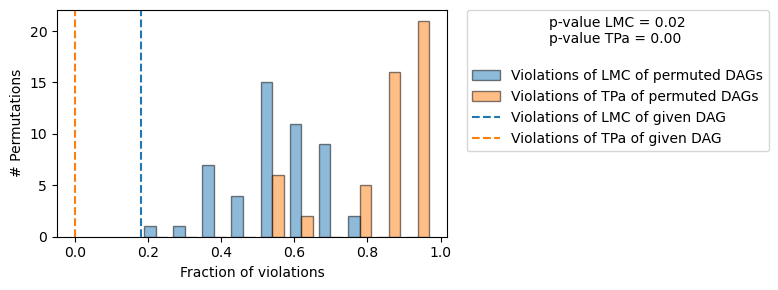

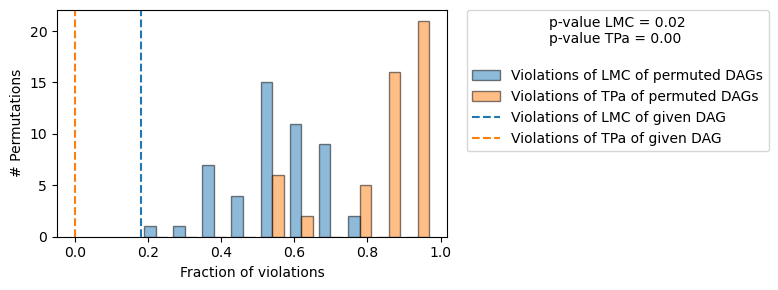

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
--- Node region
--- Node highest_education
--- Node total_early
--- Node first_ass_score
- The R2 coefficient is 0.11601212901407779.
--- Node clicks_resource_win
- The R2 coefficient is 0.018176645248287993.
--- Node clicks_url_win
- The R2 coefficient is 0.03257273389870454.
--- Node clicks_forumng_win
- The R2 coefficient is 0.4614779065042157.
--- Node clicks_homepage_win
- The R2 coefficient is 0.6814522139342669.
--- Node clicks_quiz_win
- The R2 coefficient is 0.3082488479774885.
--- Node clicks_subpage_win
- The R2 coefficient is 0.6562356734730768.
--- Node c

In [121]:
import dowhy.gcm as gcm
import pickle

# Model variables: the nodes that have a path to the outcome (background variables with no path are left out)
scm_cols = ['region', 'highest_education', 'total_early', 'first_ass_score'] + win7 + ['final_result']
dag_scm = dag.subgraph(scm_cols).copy()                      # the frozen DAG restricted to these 12 variables
df_scm = Gdf[scm_cols].astype(float)                         # gcm expects numeric data
print("nodes:", dag_scm.number_of_nodes(), "| edges:", dag_scm.number_of_edges())

# Invertible model: needed so each student keeps their own 'noise' when we ask what-if questions later
scm = gcm.InvertibleStructuralCausalModel(dag_scm)
gcm.auto.assign_causal_mechanisms(scm, df_scm)               # DoWhy picks a mechanism for every node

# Show which mechanism type was picked for each node
for n in dag_scm.nodes:
    mech = scm.causal_mechanism(n)
    print(n, "|", type(mech).__name__, "|", type(getattr(mech, "prediction_model", None)).__name__)

gcm.fit(scm, df_scm)                                         # fit every node's mechanism from the data
ev = gcm.evaluate_causal_model(scm, df_scm, compare_mechanism_baselines=True)   # slow: permutation tests, keep the laptop awake

# Save the model and the full report, then print only the lines we need
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm.pkl"), "wb") as f:
    pickle.dump(scm, f)
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_evaluation.txt"), "w") as f:
    f.write(str(ev))
for line in str(ev).splitlines():
    if any(k in line for k in ["--- Node", "R2 coefficient", "model assumption", "violates", "overall average KL"]):
        print(line)

### Stage 5.2 - Compare mechanism types: auto discrete (done), continuous linear, continuous boosted - R-squared and invertibility per node

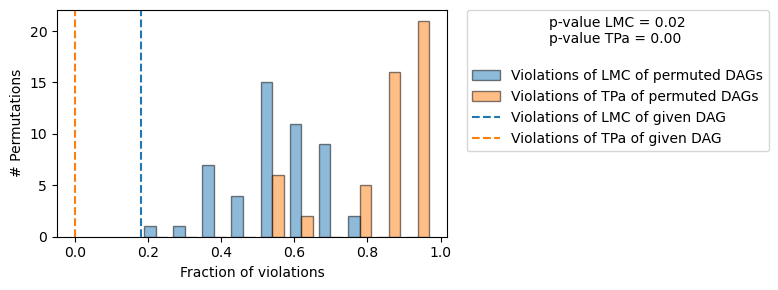

Evaluating causal mechanisms...: 100%|██████████| 12/12 [00:00<00:00, 1832.84it/s]


                node  auto discrete R2 auto discrete invertible  linear R2 linear invertible  boosted R2 boosted invertible
     first_ass_score             0.116          no (p=2.03e-06)      0.141   no (p=3.31e-05)       0.155     no (p=9.1e-07)
  clicks_forumng_win             0.461                 no (p=0)      0.522          no (p=0)       0.532           no (p=0)
 clicks_homepage_win             0.681          no (p=2.03e-06)      0.739          no (p=0)       0.747           no (p=0)
clicks_oucontent_win            -0.009                 no (p=0)      0.101          no (p=0)       0.065           no (p=0)
     clicks_quiz_win             0.308          no (p=9.99e-15)      0.324          no (p=0)       0.368           no (p=0)
 clicks_resource_win             0.018                 no (p=0)      0.119          no (p=0)       0.123           no (p=0)
  clicks_subpage_win             0.656                 no (p=0)      0.717          no (p=0)       0.708           no (p=0)
      cl

In [126]:
import re

def to_num(s):
    # The report sentences end with a full stop right after the number, so strip it before converting
    return float(s.rstrip('.'))

def parse_eval(text):
    # Pull R-squared and the invertibility test result per node out of the evaluation report text
    r2, inv, cur = {}, {}, None
    for line in text.splitlines():
        m = re.match(r'--- Node (\S+)', line)
        if m:
            cur = m.group(1)                                     # remember which node the following lines describe
            continue
        m = re.search(r'The R2 coefficient is ([\-0-9.eE+]+)', line)
        if m and cur:
            r2[cur] = to_num(m.group(1))
        m = re.search(r'assumption for node (\S+) is (not rejected|rejected) with a p-value of ([0-9.eE+\-]+)', line)
        if m:
            inv[m.group(1)] = (m.group(2), to_num(m.group(3)))
    return r2, inv

def build(variant):
    # Same frozen DAG; every non-root node gets a continuous additive-noise mechanism with the chosen regressor
    s = gcm.InvertibleStructuralCausalModel(dag_scm)
    gcm.auto.assign_causal_mechanisms(s, df_scm)                 # roots keep their empirical distributions
    for n in dag_scm.nodes:
        if dag_scm.in_degree(n) == 0:
            continue
        reg = gcm.ml.create_linear_regressor() if variant == 'linear' else gcm.ml.create_hist_gradient_boost_regressor()
        s.set_causal_mechanism(n, gcm.AdditiveNoiseModel(reg))
    return s

reports = {'auto discrete': parse_eval(str(ev))}                 # the Stage 5.1 result (ev still holds the report)
scms = {'auto discrete': scm}
for v in ['linear', 'boosted']:
    s = build(v)
    gcm.fit(s, df_scm)
    # Skip the slow structure test and KL here: we only need per-node fit and invertibility
    ev_v = gcm.evaluate_causal_model(s, df_scm, compare_mechanism_baselines=False,
                                     evaluate_causal_structure=False, evaluate_overall_kl_divergence=False)
    reports[v] = parse_eval(str(ev_v))
    scms[v] = s
    with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_{v}.pkl"), "wb") as f:
        pickle.dump(s, f)

# One row per non-root node, three versions side by side
rows = []
for n in [x for x in dag_scm.nodes if dag_scm.in_degree(x) > 0]:
    row = {'node': n}
    for v, (r2, inv) in reports.items():
        row[v + ' R2'] = round(r2.get(n, np.nan), 3)
        row[v + ' invertible'] = f"{'no' if inv.get(n, ('', 0))[0] == 'rejected' else 'yes'} (p={inv.get(n, ('', np.nan))[1]:.3g})"
    rows.append(row)
comp = pd.DataFrame(rows)
print(comp.to_string(index=False))
comp.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_mechanism_comparison.csv"), index=False)

### Stage 5.2b - Reload the three models from their saved files (each with its own graph), then verify they are really different

In [137]:
import pickle
try:
    from dowhy.graph import get_ordered_predecessors
except ImportError:
    get_ordered_predecessors = lambda g, n: sorted(g.predecessors(n))

# Each file was saved right after its own fit, so each holds the right mechanisms
paths = {'auto discrete': f"{MODULE}_checkpoint_scm.pkl",
         'linear': f"{MODULE}_checkpoint_scm_linear.pkl",
         'boosted': f"{MODULE}_checkpoint_scm_boosted.pkl"}
scms = {}
for k, fn in paths.items():
    with open(os.path.join(OUT_DIR, fn), "rb") as f:
        scms[k] = pickle.load(f)

# 1. Do the three models now have their own outcome mechanisms (and their own graph objects)?
for k, m in scms.items():
    mech = m.causal_mechanism('final_result')
    est = getattr(getattr(mech, 'prediction_model', None), 'sklearn_model', None)
    print(k, '|', type(mech).__name__, '|', type(est).__name__, '| graph id:', id(m.graph))

# 2. Linear model: effect on final_result per level of each parent (compare with the Stage 4.1 / 4.5 regressions)
lin = scms['linear'].causal_mechanism('final_result').prediction_model.sklearn_model
parents = get_ordered_predecessors(scms['linear'].graph, 'final_result')
print("\nlinear outcome mechanism, effect per level of each parent:")
print(pd.Series(lin.coef_.ravel(), index=parents).round(3).to_string())

# 3. The same what-if (start content pages) for the same five Fail students under each version
d5 = df_scm[cohort_lab == 'fail'].head(5).reset_index(drop=True)
print("\nobserved outcome:", d5['final_result'].tolist())
print("content-page level before:", d5['clicks_oucontent_win'].tolist())
for k, m in scms.items():
    out = gcm.counterfactual_samples(m, scenarios['start content pages'], observed_data=d5)
    print(k, "-> counterfactual outcome:", out['final_result'].round(3).tolist())

auto discrete | DiscreteAdditiveNoiseModel | LinearRegression | graph id: 1704978292688
linear | AdditiveNoiseModel | LinearRegression | graph id: 1704979844112
boosted | AdditiveNoiseModel | HistGradientBoostingRegressor | graph id: 1704418347344

linear outcome mechanism, effect per level of each parent:
clicks_forumng_win      0.040
clicks_homepage_win     0.140
clicks_oucontent_win    0.072
clicks_quiz_win         0.059
clicks_resource_win    -0.039
first_ass_score         0.210
highest_education       0.151

observed outcome: [1.0, 1.0, 1.0, 1.0, 1.0]
content-page level before: [0.0, 0.0, 0.0, 0.0, 0.0]
auto discrete -> counterfactual outcome: [1.0, 1.0, 1.0, 1.0, 1.0]
linear -> counterfactual outcome: [1.072, 1.072, 1.072, 1.072, 1.072]
boosted -> counterfactual outcome: [1.363, 1.095, 1.003, 1.422, 1.396]


### Stage 5.3 - What-if shifts: start quiz, forum or content pages, raise homepage visits one level, and bundles, for Fail and late-leaver students, under all three model versions

In [129]:
cohort_lab = G.loc[df_scm.index, 'cohort']          # 'fail', 'late_leaver' or 'success' for every row of df_scm
REQUIRED_GAIN = 0.5      # Fail students (observed 1) need to reach 1.5; late leavers (observed 0) need to reach 0.5

def raise_to(nodes, level=1):
    # Raise-only intervention: students already at or above `level` are left unchanged
    return {n: (lambda x, l=level: np.maximum(x, l)) for n in nodes}

three = ['clicks_quiz_win', 'clicks_forumng_win', 'clicks_oucontent_win']
homepage_up = {'clicks_homepage_win': lambda x: np.minimum(x + 1, 3)}      # one level more regular, capped at level 3
scenarios = {
    'start quiz': raise_to(['clicks_quiz_win']),
    'start forum': raise_to(['clicks_forumng_win']),
    'start content pages': raise_to(['clicks_oucontent_win']),
    'homepage up one level': homepage_up,
    'quiz + forum + content': raise_to(three),
    'all four': {**raise_to(three), **homepage_up},
}

rows = []                                            # reset before every rerun
for model_name, model in scms.items():               # 'auto discrete', 'linear', 'boosted' from Stage 5.2
    for cname in ['fail', 'late_leaver']:
        d = df_scm[cohort_lab == cname].reset_index(drop=True)
        for sname, iv in scenarios.items():
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)      # student-level what-if (approximate, see notes)
            shift = cf['final_result'].values - d['final_result'].values      # change in the outcome for each student
            elig = np.zeros(len(d), dtype=bool)                               # students for whom the intervention changes something
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, 'n': len(d),
                         '% affected': round(elig.mean() * 100, 1),
                         'mean shift (all)': round(shift.mean(), 3),
                         'mean shift (affected)': round(shift[elig].mean(), 3) if elig.any() else np.nan,
                         '% shift >= 0.5': round((shift >= REQUIRED_GAIN).mean() * 100, 1)})
res_l1 = pd.DataFrame(rows)
res_l1.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_whatif_shifts.csv"), index=False)

print("MAIN MODEL (linear):")
print(res_l1[res_l1.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nMean shift among affected students, by model version (robustness check):")
print(res_l1.pivot_table(index=['cohort', 'scenario'], columns='model', values='mean shift (affected)').round(3).to_string())

MAIN MODEL (linear):
     cohort               scenario    n  % affected  mean shift (all)  mean shift (affected)  % shift >= 0.5
       fail             start quiz 1372        38.3             0.112                  0.292             1.8
       fail            start forum 1372        48.6             0.098                  0.201             1.8
       fail    start content pages 1372        92.1             0.345                  0.374            35.9
       fail  homepage up one level 1372        87.0             0.195                  0.225             5.6
       fail quiz + forum + content 1372        93.4             0.417                  0.447            41.8
       fail               all four 1372        96.9             0.504                  0.521            51.5
late_leaver             start quiz  529        28.2             0.093                  0.330             2.3
late_leaver            start forum  529        35.9             0.090                  0.251             3.

### Stage 5.3b - Diagnose the identical shifts: are the three models really different, what do the outcome coefficients look like, and do raw counterfactuals differ?

In [139]:
# get_ordered_predecessors gives the parents of a node in the exact order the model uses them internally
try:
    from dowhy.graph import get_ordered_predecessors
except ImportError:
    get_ordered_predecessors = lambda g, n: sorted(g.predecessors(n))      # same ordering (sorted by node name)

# 1. Are the three versions really different objects, with different outcome mechanisms?
for k, m in scms.items():
    mech = m.causal_mechanism('final_result')
    est = getattr(getattr(mech, 'prediction_model', None), 'sklearn_model', None)
    print(k, '| object id:', id(m), '|', type(mech).__name__, '|', type(est).__name__)

# 2. Linear model: coefficients of the outcome mechanism = change in final_result per level of each parent
lin = scms['linear'].causal_mechanism('final_result').prediction_model.sklearn_model
parents = get_ordered_predecessors(scms['linear'].graph, 'final_result')
print("\nlinear outcome mechanism, effect per level of each parent:")
print(pd.Series(lin.coef_.ravel(), index=parents).round(3).to_string())

# 3. Same what-if (start content pages) for the same five Fail students under each version
d5 = df_scm[cohort_lab == 'fail'].head(5).reset_index(drop=True)
print("\nobserved outcome:", d5['final_result'].tolist())
print("content-page level before:", d5['clicks_oucontent_win'].tolist())
for k, m in scms.items():
    out = gcm.counterfactual_samples(m, scenarios['start content pages'], observed_data=d5)
    print(k, "-> counterfactual outcome:", out['final_result'].round(3).tolist(),
          "| content-page level after:", out['clicks_oucontent_win'].round(2).tolist())

auto discrete | object id: 1704422434320 | DiscreteAdditiveNoiseModel | LinearRegression
linear | object id: 1704319312144 | AdditiveNoiseModel | LinearRegression
boosted | object id: 1704957907664 | AdditiveNoiseModel | HistGradientBoostingRegressor

linear outcome mechanism, effect per level of each parent:
clicks_forumng_win      0.040
clicks_homepage_win     0.140
clicks_oucontent_win    0.072
clicks_quiz_win         0.059
clicks_resource_win    -0.039
first_ass_score         0.210
highest_education       0.151

observed outcome: [1.0, 1.0, 1.0, 1.0, 1.0]
content-page level before: [0.0, 0.0, 0.0, 0.0, 0.0]
auto discrete -> counterfactual outcome: [1.0, 1.0, 1.0, 1.0, 1.0] | content-page level after: [1.0, 1.0, 1.0, 1.0, 1.0]
linear -> counterfactual outcome: [1.072, 1.072, 1.072, 1.072, 1.072] | content-page level after: [1.0, 1.0, 1.0, 1.0, 1.0]
boosted -> counterfactual outcome: [1.363, 1.095, 1.003, 1.422, 1.396] | content-page level after: [1.0, 1.0, 1.0, 1.0, 1.0]


### Stage 5.2c - Rebuild the models with participation coding for quiz, forum and content pages (0/1), each model on its own copy of the graph

In [142]:
# Quiz, forum and content pages become 0 = none, 1 = any activity (Stage 4.5 showed only starting matters for these)
part_nodes = ['clicks_quiz_win', 'clicks_forumng_win', 'clicks_oucontent_win']
df_scm2 = df_scm.copy()
for c in part_nodes:
    df_scm2[c] = (df_scm2[c] > 0).astype(float)

def build2(variant):
    # Each model gets its OWN copy of the graph, so fitting one cannot overwrite another (the earlier bug)
    s = gcm.InvertibleStructuralCausalModel(dag_scm.copy())
    gcm.auto.assign_causal_mechanisms(s, df_scm2)                # roots keep empirical distributions
    for n in dag_scm.nodes:
        if dag_scm.in_degree(n) == 0:
            continue
        reg = gcm.ml.create_linear_regressor() if variant == 'linear' else gcm.ml.create_hist_gradient_boost_regressor()
        s.set_causal_mechanism(n, gcm.AdditiveNoiseModel(reg))
    return s

scms2, reports2 = {}, {}
for v in ['linear', 'boosted']:
    s = build2(v)
    gcm.fit(s, df_scm2)
    ev_v = gcm.evaluate_causal_model(s, df_scm2, compare_mechanism_baselines=False,
                                     evaluate_causal_structure=False, evaluate_overall_kl_divergence=False)
    scms2[v] = s
    reports2[v] = parse_eval(str(ev_v))                          # parse_eval was defined in Stage 5.2
    with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_{v}_participation.pkl"), "wb") as f:
        pickle.dump(s, f)

# Outcome mechanism of the linear model: effect of each parent (quiz, forum and content pages are now 'start vs none')
lin2 = scms2['linear'].causal_mechanism('final_result').prediction_model.sklearn_model
par2 = get_ordered_predecessors(scms2['linear'].graph, 'final_result')
print("linear outcome mechanism (participation coding):")
print(pd.Series(lin2.coef_.ravel(), index=par2).round(3).to_string())

# Fit and invertibility per node, both versions side by side
rows = []
for n in [x for x in dag_scm.nodes if dag_scm.in_degree(x) > 0]:
    row = {'node': n}
    for v, (r2, inv) in reports2.items():
        row[v + ' R2'] = round(r2.get(n, np.nan), 3)
        row[v + ' invertible'] = f"{'no' if inv.get(n, ('', 0))[0] == 'rejected' else 'yes'} (p={inv.get(n, ('', np.nan))[1]:.3g})"
    rows.append(row)
print("\n", pd.DataFrame(rows).to_string(index=False))

Evaluating causal mechanisms...: 100%|██████████| 12/12 [00:00<00:00, 4775.30it/s]


linear outcome mechanism (participation coding):
clicks_forumng_win      0.089
clicks_homepage_win     0.141
clicks_oucontent_win    0.169
clicks_quiz_win         0.207
clicks_resource_win    -0.040
first_ass_score         0.199
highest_education       0.147

                 node  linear R2 linear invertible  boosted R2 boosted invertible
     first_ass_score      0.142   no (p=3.48e-06)       0.157    no (p=2.18e-06)
  clicks_forumng_win      0.373          no (p=0)       0.451           no (p=0)
 clicks_homepage_win      0.679          no (p=0)       0.691           no (p=0)
clicks_oucontent_win      0.104          no (p=0)       0.073           no (p=0)
     clicks_quiz_win      0.391          no (p=0)       0.591           no (p=0)
 clicks_resource_win      0.119          no (p=0)       0.123           no (p=0)
  clicks_subpage_win      0.720          no (p=0)       0.712           no (p=0)
      clicks_url_win      0.123          no (p=0)       0.123           no (p=0)
        fi

### Stage 5.3 (rerun) - What-if shifts with the corrected models: start quiz, forum or content pages, homepage one level up, and bundles, for Fail and late-leaver students

In [145]:
rows = []                                            # reset before every rerun
for model_name, model in scms2.items():              # two genuinely different models now
    for cname in ['fail', 'late_leaver']:
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)          # same students, participation-coded values
        for sname, iv in scenarios.items():                              # scenarios were defined in the earlier 5.3 cell
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)  # student-level what-if (approximate)
            shift = cf['final_result'].values - d['final_result'].values
            elig = np.zeros(len(d), dtype=bool)                          # students for whom the change actually alters a value
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, 'n': len(d),
                         '% affected': round(elig.mean() * 100, 1),
                         'mean shift (all)': round(shift.mean(), 3),
                         'mean shift (affected)': round(shift[elig].mean(), 3) if elig.any() else np.nan})
res2 = pd.DataFrame(rows)
res2.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_whatif_shifts_participation.csv"), index=False)

print("MAIN MODEL (linear, participation coding):")
print(res2[res2.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nMean shift among affected students, linear vs boosted (they should now differ):")
print(res2.pivot_table(index=['cohort', 'scenario'], columns='model', values='mean shift (affected)').round(3).to_string())
print("\nRegression benchmark (Stage 4.5, all activities held fixed): quiz 0.220, content pages 0.146, forum 0.096, homepage 0.118 per level")

MAIN MODEL (linear, participation coding):
     cohort               scenario    n  % affected  mean shift (all)  mean shift (affected)
       fail             start quiz 1372        38.3             0.080                  0.209
       fail            start forum 1372        48.6             0.106                  0.218
       fail    start content pages 1372        92.1             0.156                  0.169
       fail  homepage up one level 1372        87.0             0.165                  0.190
       fail quiz + forum + content 1372        93.4             0.330                  0.353
       fail               all four 1372        96.9             0.473                  0.488
late_leaver             start quiz  529        28.2             0.059                  0.209
late_leaver            start forum  529        35.9             0.078                  0.218
late_leaver    start content pages  529        90.5             0.153                  0.169
late_leaver  homepage up on

### Stage 5.4 - Profile-based probability view: chance of reaching the target before and after each action (noise drawn from the whole sample, no student-level noise recovery)

In [150]:
def outcome_mean(model, data):
    # Predicted outcome without noise, from the fitted outcome mechanism and the student's parent values.
    # .ravel() flattens the result: the linear model returns a column (n, 1), the boosted one a flat list (n,)
    mech = model.causal_mechanism('final_result')
    par = get_ordered_predecessors(model.graph, 'final_result')
    return np.asarray(mech.prediction_model.predict(data[par].to_numpy())).ravel()

def prob_reach(f_vals, resid, T):
    # For each student: the share of noise draws for which predicted outcome + noise reaches the target T
    assert f_vals.ndim == 1 and resid.ndim == 1, "predictions and residuals must both be flat lists"
    return (f_vals[:, None] + resid[None, :] >= T).mean(axis=1)

targets = {'fail': 1.5, 'late_leaver': 0.5}        # Fail: reach Pass (>= 1.5); late leaver: stay and not withdraw (>= 0.5)
rows, calib = [], []                               # reset before every rerun

for model_name, model in scms2.items():
    f_all = outcome_mean(model, df_scm2)
    resid = df_scm2['final_result'].values - f_all            # pool of unexplained variation, all enrolled students
    # Sanity check: the model's average chance across ALL students should match the real shares
    for T, real in [(1.5, (df_scm2.final_result >= 2).mean()), (0.5, (df_scm2.final_result >= 1).mean())]:
        calib.append({'model': model_name, 'target': T, 'model average': round(prob_reach(f_all, resid, T).mean(), 3),
                      'real share': round(real, 3)})
    for cname, T in targets.items():
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        f0 = outcome_mean(model, d)                           # predicted outcome now
        p0 = prob_reach(f0, resid, T)                         # chance of reaching the target now
        for sname, iv in scenarios.items():
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)
            delta = cf['final_result'].values - d['final_result'].values   # model-predicted shift incl. downstream effects
            p1 = prob_reach(f0 + delta, resid, T)             # chance after the action
            elig = np.zeros(len(d), dtype=bool)
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, '% affected': round(elig.mean() * 100, 1),
                         'chance before (%)': round(p0.mean() * 100, 1), 'chance after (%)': round(p1.mean() * 100, 1),
                         'gain, all (pts)': round((p1 - p0).mean() * 100, 1),
                         'gain, affected (pts)': round((p1 - p0)[elig].mean() * 100, 1) if elig.any() else np.nan})

print("Sanity check (model average vs real share):")
print(pd.DataFrame(calib).to_string(index=False))
res_p = pd.DataFrame(rows)
res_p.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_probability_gains.csv"), index=False)
print("\nMAIN MODEL (linear):")
print(res_p[res_p.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nGain among affected students (percentage points), linear vs boosted:")
print(res_p.pivot_table(index=['cohort', 'scenario'], columns='model', values='gain, affected (pts)').round(1).to_string())

Sanity check (model average vs real share):
  model  target  model average  real share
 linear     1.5          0.583       0.578
 linear     0.5          0.885       0.882
boosted     1.5          0.569       0.578
boosted     0.5          0.892       0.882

MAIN MODEL (linear):
     cohort               scenario  % affected  chance before (%)  chance after (%)  gain, all (pts)  gain, affected (pts)
       fail             start quiz        38.3               44.6              48.7              4.1                  10.6
       fail            start forum        48.6               44.6              50.1              5.5                  11.3
       fail    start content pages        92.1               44.6              52.5              7.9                   8.6
       fail  homepage up one level        87.0               44.6              52.9              8.3                   9.5
       fail quiz + forum + content        93.4               44.6              62.9             18.3    

### Stage 5.5 - Recourse plans: for each student, the smallest set of actions that raises the chance of the target by at least g points (coverage by number of actions allowed)

In [153]:
from itertools import combinations
from collections import Counter

# The four actions we may recommend, as raise-only interventions (defined in Stage 5.3)
actions = {'quiz': raise_to(['clicks_quiz_win']), 'forum': raise_to(['clicks_forumng_win']),
           'content': raise_to(['clicks_oucontent_win']), 'homepage': homepage_up}

def effective(d, iv):
    # Which students does this action actually change? (someone already doing it is not helped by being told to do it)
    e = np.zeros(len(d), dtype=bool)
    for n, fn in iv.items():
        e |= (np.asarray(fn(d[n].values)) != d[n].values)
    return e

gains_grid = [5, 10, 15, 20]                     # minimum improvement in the chance of the target, in percentage points
cover_rows, plan_counts = [], {}                 # reset before every rerun

for model_name, model in scms2.items():
    f_all = outcome_mean(model, df_scm2)
    resid = df_scm2['final_result'].values - f_all
    for cname, T in targets.items():
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        f0 = outcome_mean(model, d)
        p0 = prob_reach(f0, resid, T)
        elig = {a: effective(d, iv) for a, iv in actions.items()}
        # Gain (in points) of every combination of actions, and whether every action in it applies to the student
        plan_gain, plan_valid = {}, {}
        for r in range(1, len(actions) + 1):
            for S in combinations(actions, r):
                iv = {}
                for a in S:
                    iv.update(actions[a])
                cf = gcm.counterfactual_samples(model, iv, observed_data=d)
                delta = cf['final_result'].values - d['final_result'].values
                plan_gain[S] = (prob_reach(f0 + delta, resid, T) - p0) * 100
                plan_valid[S] = np.all([elig[a] for a in S], axis=0)
        none_available = ~np.any(list(elig.values()), axis=0)
        # Coverage: share of students with a valid plan of at most k actions reaching a gain of at least g points
        for g in gains_grid:
            row = {'model': model_name, 'cohort': cname, 'min gain (pts)': g}
            for k in range(1, len(actions) + 1):
                ok = np.zeros(len(d), dtype=bool)
                for S in plan_gain:
                    if len(S) <= k:
                        ok |= plan_valid[S] & (plan_gain[S] >= g)
                row[f'<= {k} actions (%)'] = round(ok.mean() * 100, 1)
            cover_rows.append(row)
        # Most common minimal plan at a 10-point gain: fewest actions first, ties broken by the larger gain
        plans = []
        for i in range(len(d)):
            best = None
            for S in plan_gain:
                if plan_valid[S][i] and plan_gain[S][i] >= 10:
                    key = (len(S), -plan_gain[S][i])
                    if best is None or key < best[0]:
                        best = (key, S)
            plans.append(' + '.join(best[1]) if best else ('no action applies' if none_available[i] else 'no plan reaches 10 pts'))
        plan_counts[(model_name, cname)] = Counter(plans)

cover = pd.DataFrame(cover_rows)
cover.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_recourse_coverage.csv"), index=False)
print("Share of students with a plan reaching the gain, by number of actions allowed:")
print(cover.to_string(index=False))
for (m, c), cnt in plan_counts.items():
    if m == 'linear':
        print(f"\nMost common minimal plans, {c}, gain >= 10 points ({m} model):")
        for plan, n in cnt.most_common(6):
            print(f"  {plan}: {n} students ({n / sum(cnt.values()) * 100:.1f}%)")

Share of students with a plan reaching the gain, by number of actions allowed:
  model      cohort  min gain (pts)  <= 1 actions (%)  <= 2 actions (%)  <= 3 actions (%)  <= 4 actions (%)
 linear        fail               5              95.1              95.7              95.7              95.7
 linear        fail              10              40.6              83.8              83.8              83.8
 linear        fail              15              19.2              50.4              64.2              64.2
 linear        fail              20               0.0              40.0              54.3              55.2
 linear late_leaver               5              24.2              32.1              43.1              43.1
 linear late_leaver              10               0.0              19.7              21.6              22.3
 linear late_leaver              15               0.0               0.0              15.5              15.7
 linear late_leaver              20               0.0    

### Stage 6.1 - Early leavers: build the table (registration-time factors only) and show the early-leaving rate by factor

In [156]:
import re

# One row per student (all 5,617). Outcome: unregistered on or before day 28 (missing unregistration date = never left)
E = X[keys + demo + ['date_registration', 'date_unregistration']].copy()
E['left_early'] = (E.date_unregistration <= 28).astype(int)      # NaN <= 28 is False, so students who never left get 0
print("students:", len(E), "| left by day 28:", int(E.left_early.sum()), f"({E.left_early.mean() * 100:.1f}%)")

# ---- Readable categories for every factor (all known at or before the start of the course) ----
E['imd_band'] = E.imd_band.replace({'Oct-20': '10-20%', '10-20': '10-20%'}).fillna('missing')   # 'Oct-20' is the date-mangled 10-20% band
edu_order = ['No Formal quals', 'Lower Than A Level', 'A Level or Equivalent', 'HE Qualification', 'Post Graduate Qualification']
E['highest_education'] = pd.Categorical(E.highest_education, categories=edu_order, ordered=True)
E['studied_credits'] = pd.cut(E.studied_credits, bins=[0, 60, 90, np.inf], labels=['<=60', '61-90', '>90'])
E['num_of_prev_attempts'] = E.num_of_prev_attempts.clip(upper=2).map({0: '0', 1: '1', 2: '2+'})
# Registration timing: days before the course start (negative registration dates mean registered before the start)
days_before = (-E.date_registration).fillna((-E.date_registration).median())     # a few missing dates get the median
E['reg_timing'] = pd.cut(days_before, bins=[-np.inf, 0, 30, 60, 90, np.inf],
                         labels=['day 0 or later', '1-30 days before', '31-60 days before',
                                 '61-90 days before', 'over 90 days before'])
factors = ['gender', 'age_band', 'highest_education', 'imd_band', 'disability',
           'region', 'num_of_prev_attempts', 'studied_credits', 'reg_timing']

# ---- Early-leaving rate by level of each factor (the simple, unadjusted view) ----
for v in factors:
    t = E.groupby(v, observed=True).left_early.agg(n='size', early_leavers='sum', rate_pct=lambda s: s.mean() * 100).round(1)
    print(f"\n{v}")
    print(t.to_string())
E.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_leaver_table.csv"), index=False)

students: 5617 | left by day 28: 970 (17.3%)

gender
           n  early_leavers  rate_pct
gender                               
F       4973            858      17.3
M        644            112      17.4

age_band
             n  early_leavers  rate_pct
age_band                               
0-35      3768            714      18.9
35-55     1846            256      13.9
55<=         3              0       0.0

highest_education
                                n  early_leavers  rate_pct
highest_education                                         
No Formal quals                78             19      24.4
Lower Than A Level           2578            522      20.2
A Level or Equivalent        2341            346      14.8
HE Qualification              610             82      13.4
Post Graduate Qualification    10              1      10.0

imd_band
            n  early_leavers  rate_pct
imd_band                              
0-10%     747            157      21.0
10-20%    703            1

### Stage 6.2 - Early leavers: effect of each factor on the chance of leaving early, all factors adjusted for each other (percentage points)

In [159]:
import statsmodels.formula.api as smf

# Linear probability model: each coefficient = change in the chance of leaving early (in points) versus a reference group,
# with every other factor held fixed. Robust (HC1) standard errors. Reference group = the most common level of each factor.
for v in factors:
    E[v] = E[v].astype(str)                                       # plain text categories for the formula
refs = {v: E[v].value_counts().idxmax() for v in factors}
formula = 'left_early ~ ' + ' + '.join(f"C({v}, Treatment(reference='{refs[v]}'))" for v in factors)
m = smf.ols(formula, data=E).fit(cov_type='HC1')
ci = m.conf_int()

rows = []
for name in m.params.index:
    if name == 'Intercept':
        continue
    var, ref, lvl = re.match(r"C\((\w+), Treatment\(reference='(.*)'\)\)\[T\.(.*)\]", name).groups()
    rows.append({'factor': var, 'level': lvl, 'compared with': ref,
                 'effect (pts)': round(m.params[name] * 100, 1),
                 'CI low': round(ci.loc[name, 0] * 100, 1), 'CI high': round(ci.loc[name, 1] * 100, 1),
                 'clear': (ci.loc[name, 0] > 0) or (ci.loc[name, 1] < 0)})       # interval excludes zero
eff = pd.DataFrame(rows)
eff.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_leaver_effects.csv"), index=False)
print("Factors with a clear effect (interval excludes zero), largest first:")
print(eff[eff.clear].assign(abs_eff=lambda d: d['effect (pts)'].abs())
      .sort_values('abs_eff', ascending=False).drop(columns=['abs_eff', 'clear']).to_string(index=False))
print("\nFactors with no clear effect (levels):", eff[~eff.clear].groupby('factor').size().to_dict())

Factors with a clear effect (interval excludes zero), largest first:
           factor                 level       compared with  effect (pts)  CI low  CI high
       reg_timing        day 0 or later over 90 days before         -24.7   -30.2    -19.3
         age_band                  55<=                0-35         -16.5   -23.1    -10.0
       reg_timing      1-30 days before over 90 days before         -15.1   -17.8    -12.4
       reg_timing     31-60 days before over 90 days before         -11.3   -14.1     -8.5
           region  North Western Region East Anglian Region          10.5     5.4     15.7
           region                 Wales East Anglian Region         -10.1   -13.7     -6.5
       reg_timing     61-90 days before over 90 days before          -8.2   -11.4     -5.0
           region         London Region East Anglian Region           6.0     1.3     10.7
highest_education A Level or Equivalent  Lower Than A Level          -5.6    -7.7     -3.5
  studied_credits    

### Stage 6.3 - Early leavers: how well can registration-time factors rank students by risk? (5-fold cross-validated) and how many early leavers a short outreach list would reach

In [162]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

Xr = pd.get_dummies(E[factors], drop_first=True).astype(float)    # one 0/1 column per factor level
y = E.left_early.values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # every student is scored by a model that never saw them

models = {'logistic': LogisticRegression(max_iter=2000),
          'boosted trees': HistGradientBoostingClassifier(random_state=42)}
base = y.mean()
for name, mdl in models.items():
    risk = cross_val_predict(mdl, Xr, y, cv=cv, method='predict_proba')[:, 1]    # out-of-sample risk for every student
    print(f"\n{name}: cross-validated AUC = {roc_auc_score(y, risk):.3f} (0.5 = no better than chance)")
    order = np.argsort(-risk)                                      # highest predicted risk first
    rows = []
    for pct in [10, 20, 30, 40]:
        top = order[: int(len(y) * pct / 100)]
        rows.append({'contact top % by risk': pct, 'students': len(top),
                     'early-leave rate in this group (%)': round(y[top].mean() * 100, 1),
                     'share of all early leavers reached (%)': round(y[top].sum() / y.sum() * 100, 1)})
    print(pd.DataFrame(rows).to_string(index=False))
print(f"\nBaseline early-leave rate: {base * 100:.1f}%")


logistic: cross-validated AUC = 0.680 (0.5 = no better than chance)
 contact top % by risk  students  early-leave rate in this group (%)  share of all early leavers reached (%)
                    10       561                                34.0                                    19.7
                    20      1123                                31.2                                    36.1
                    30      1685                                29.6                                    51.3
                    40      2246                                26.5                                    61.4

boosted trees: cross-validated AUC = 0.636 (0.5 = no better than chance)
 contact top % by risk  students  early-leave rate in this group (%)  share of all early leavers reached (%)
                    10       561                                26.0                                    15.1
                    20      1123                                26.0                          

### Stage 6.4 - Early leavers, fair version: students enrolled on day 0, outcome = unregistered during days 0-28, presentation controlled

In [165]:
# Fair window: students enrolled on day 0 (registered by then, not yet unregistered); everyone has the same 28 days at risk
E2 = E[(E.date_registration.fillna(-999) <= 0) &
       (E.date_unregistration.isna() | (E.date_unregistration >= 0))].copy()
E2['left_28'] = (E2.date_unregistration <= 28).astype(int)      # left during days 0-28
E2['age_band'] = E2.age_band.replace({'55<=': '35-55'})          # 3 students: merged into the neighbouring group
E2['highest_education'] = E2.highest_education.replace({'Post Graduate Qualification': 'HE Qualification'})   # 10 students
print("enrolled on day 0:", len(E2), "| left in days 0-28:", int(E2.left_28.sum()), f"({E2.left_28.mean() * 100:.1f}%)")

# Early-leaving rate by presentation and by registration timing in the fair window
rate = lambda s: s.mean() * 100
print("\nrate by presentation:")
print(E2.groupby('code_presentation').left_28.agg(n='size', rate_pct=rate).round(1).to_string())
print("\nrate by registration timing:")
print(E2.groupby('reg_timing').left_28.agg(n='size', rate_pct=rate).round(1).to_string())

# Adjusted effects: all factors plus presentation, versus the most common level of each (points)
factors2 = factors + ['code_presentation']
refs2 = {v: E2[v].value_counts().idxmax() for v in factors2}
formula2 = 'left_28 ~ ' + ' + '.join(f"C({v}, Treatment(reference='{refs2[v]}'))" for v in factors2)
m2 = smf.ols(formula2, data=E2).fit(cov_type='HC1')
ci2 = m2.conf_int()
rows = []
for name in m2.params.index:
    if name == 'Intercept':
        continue
    var, ref, lvl = re.match(r"C\((\w+), Treatment\(reference='(.*)'\)\)\[T\.(.*)\]", name).groups()
    rows.append({'factor': var, 'level': lvl, 'compared with': ref, 'effect (pts)': round(m2.params[name] * 100, 1),
                 'CI low': round(ci2.loc[name, 0] * 100, 1), 'CI high': round(ci2.loc[name, 1] * 100, 1),
                 'clear': (ci2.loc[name, 0] > 0) or (ci2.loc[name, 1] < 0)})
eff2 = pd.DataFrame(rows)
eff2.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_leaver_effects_fair_window.csv"), index=False)
print("\nFactors with a clear effect (interval excludes zero), largest first:")
print(eff2[eff2.clear].assign(a=lambda d: d['effect (pts)'].abs()).sort_values('a', ascending=False)
      .drop(columns=['a', 'clear']).to_string(index=False))

# Risk ranking in the fair window (logistic, 5-fold cross-validated), with the outreach-list table
Xr2 = pd.get_dummies(E2[factors2], drop_first=True).astype(float)
y2 = E2.left_28.values
risk2 = cross_val_predict(LogisticRegression(max_iter=2000), Xr2, y2,
                          cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), method='predict_proba')[:, 1]
print(f"\ncross-validated AUC (fair window) = {roc_auc_score(y2, risk2):.3f}")
order2 = np.argsort(-risk2)
out = []
for pct in [10, 20, 30, 40]:
    top = order2[: int(len(y2) * pct / 100)]
    out.append({'contact top % by risk': pct, 'students': len(top),
                'early-leave rate in group (%)': round(y2[top].mean() * 100, 1),
                'share of early leavers reached (%)': round(y2[top].sum() / y2.sum() * 100, 1)})
print(pd.DataFrame(out).to_string(index=False))
print(f"baseline rate: {y2.mean() * 100:.1f}%")

enrolled on day 0: 4959 | left in days 0-28: 351 (7.1%)

rate by presentation:
                      n  rate_pct
code_presentation                
2013B              1636       7.0
2013J              1985       8.5
2014B              1338       5.2

rate by registration timing:
                        n  rate_pct
reg_timing                         
1-30 days before     1397       5.9
31-60 days before    1410       7.5
61-90 days before     926       5.7
over 90 days before  1226       8.9

Factors with a clear effect (interval excludes zero), largest first:
           factor                 level      compared with  effect (pts)  CI low  CI high
           region  North Western Region              Wales          11.2     7.4     15.0
           region         London Region              Wales           8.6     5.4     11.7
           region      Yorkshire Region              Wales           8.0     4.5     11.5
           region          South Region              Wales           7.5   

# BBB Final Summary - RQ4 (Counterfactual Reasoning and Recourse)

Module: BBB (Social Sciences). Base module for RQ4, chosen because AAA was too small.
Status: BBB complete (whole-course pilot + checkpoint pipeline + early-leaver analysis). Next module: CCC.

---

## 1. The question and the rules

**Question:** what could have helped BBB students who failed or withdrew?

**Rules given by the professor (apply to every module):**
- Marks are never changed. Only student activity on the course site (VLE clicks) can be changed.
- Background information (age, region, education, deprivation band, credits, previous attempts) stays fixed. `studied_credits` is immutable.
- Use a bigger module as the base, because AAA was too small.
- Fail and Withdrawn students are handled separately. They are never pooled into one group.
- Domain-wise results first, combined results second (this was the RQ3 order; for RQ4 the final design below replaced it).

---

## 2. Data

- Presentations used: 2013B, 2013J, 2014B (2014J excluded earlier because its assessment count did not match).
- 5,617 students: Withdrawn 1,639; Fail 1,376; Pass 2,105; Distinction 497.
- Source files: `studentInfo`, `studentRegistration`, `studentVle` (read in chunks), `vle`, `assessments`, `studentAssessment`.
- Data quirk: in the raw `studentInfo.csv` the 10-20% deprivation band is stored as `Oct-20` (date-mangled). It must be mapped to band 1.

---

## 3. Version 1 - whole-course analysis (pilot, kept as a comparison)

**What it did:** fitted invertible causal models on the whole-course graphs (DAG1 demographics, DAG3 individual clicks, combined DAG), asked "what if a student had done more", and used DiCE for recourse with every suggestion checked through the causal model.

**Main results:**
- Raising quiz clicks to the typical Success level (about 79) would have moved about 77% of Withdrawn and 70% of Fail students to Pass. Other single click types did almost nothing.
- Threshold: no change until about 50 quiz clicks; steep gain between 50 and 70; no extra gain beyond about 70. The raw data shows the same jump (pass rate 27% at 45-50 clicks, 59% at 50-55, 80% at 60-70).
- DiCE suggestions looked valid 96-98% of the time but only 66-79% held up after the causal check. DiCE overshot (median quiz target about 87 clicks, when about 50 was enough).
- Combined model: raising `total_clicks` to the Success median bin reached 60% of Withdrawn and 49% of Fail.
- DAG1 (demographics) was too weak for counterfactuals: reported as "not estimable".

**Why it was replaced:** clicks were counted over the whole course, but many Withdrawn students left very early.
- 37.7% of Withdrawn students left before day 0 (before the course started); 52.4% by day 14; 59.1% by day 28. Median day of leaving: 10.5.
- Only 11.3% of the pre-start leavers appear in any other registration in the dataset (7.1% in a later BBB presentation), so they are mostly real dropouts.
- For these students, low clicks are a result of leaving, not a cause. Version 1 is therefore an upper limit and not something a teacher could act on.
- Removing the students who left before day 56 cut the quiz effect per bin from 0.512 to 0.197 (same simple model), which confirms the inflation.

---

## 4. Version 2 - checkpoint approach (the main BBB result)

**Idea:** stand at the end of week 4 (day 28) and look only at students still enrolled. Recommend actions for weeks 5 to 8 (days 29-56), when a teacher could still step in.

**Cohorts (never pooled):**

| Cohort | Size | Question | Analysis |
|---|---|---|---|
| Early leavers (left by day 28) | 968 | Who leaves early? | Risk analysis only (no click recourse is possible) |
| Mid leavers (left days 29-56) | 142 | - | Excluded from click analyses (window cut short) |
| Late leavers (left after day 56) | 529 | What activity is linked to staying? | Click recourse, target "stays enrolled" |
| Fail (enrolled at day 56) | 1,372 | What moves a Fail student to Pass? | Click recourse, target "reaches Pass" |
| Success (reference) | 2,601 | Comparison group | Reference only |
| Other | 5 | - | Dropped |

**Graph sample:** the 4,502 students enrolled at day 56 (Fail + late leavers + Success). One graph and one causal model serve both recourse targets (Fail to Pass: outcome of at least 1.5; late leaver to staying: outcome of at least 0.5).

---

## 5. Findings

### 5.1 The at-risk students are visible by week 4
- Total clicks up to day 28 (quartiles, lowest to highest): pass rate 33.4% to 73.6%; fail rate 49.0% to 14.7%.
- At day 56: pass rate 29.8% to 76.4%. Students with zero quiz clicks by day 56 (634 students) passed only 9.8% of the time.
- Median clicks (up to day 28 / days 29-56): Success 161 / 102; Late leavers 95 / 51; Fail 63 / 29; Mid leavers 79 / 2.5; Early leavers 0 / 0.
- Of eventual Withdrawn students, only 671 (41%) are still enrolled at day 28 and 529 (32%) at day 56. Of Fail students, 1,372 of 1,376 are.
- Early quiz activity overlaps heavily with first-assessment submission (98.3% of students with quiz clicks vs 48.1% of zero-quiz students submitted the first TMA), so the first assessment is kept in the model as fixed context.

### 5.2 Causal graph (PC, G-square test, alpha 0.05, time-ordered background knowledge)
- 18 variables: 8 background, early clicks (day 28), first assessment score, 7 window activities, final result.
- Tiers: background, then early engagement and first assessment, then window activities, then outcome. Nothing can point backwards in time.
- 27 edges from PC (24 directed, 3 undirected); no rule violations; only `disability` isolated.
- Direct parents of the outcome: `highest_education`, `first_ass_score`, `clicks_homepage_win`, `clicks_quiz_win`. These stayed the same across all codings and across alpha 0.05 and 0.10. At alpha 0.10 `imd_band` is added.
- Directions between activities inside the click group are not stable (several reversed with the coding or the alpha). Only the set of direct parents of the outcome is stable.
- Domain-knowledge additions to PC (flagged): 10 edges from early clicks and first assessment into every window activity; 3 edges from forum, content pages and resource into the outcome (activities with a clear effect when all others are held fixed). Final graph: 37 edges.

### 5.3 Effects on the final result (0-3 scale, per one-level step, graph-adjusted; all refutations passed)

| Variable | Effect | 95% interval |
|---|---|---|
| First assessment score | 0.273 | 0.249 to 0.298 |
| Highest education | 0.232 | 0.198 to 0.267 |
| Early clicks (to day 28) | 0.201 | 0.180 to 0.222 |
| Homepage | 0.178 | 0.135 to 0.221 |
| Forum | 0.127 | 0.099 to 0.156 |
| Content pages | 0.074 | 0.044 to 0.104 |
| URL | 0.069 | 0.048 to 0.090 |
| Quiz | 0.054 | 0.028 to 0.079 |
| Subpage | 0.043 | 0.006 to 0.079 |
| Resource | 0.031 | 0.010 to 0.053 |

- Robustness check: when early clicks and the first assessment are also adjusted for, homepage, forum, quiz and URL stay stable, subpage halves and resource nearly vanishes. This is why the early-context edges were added.
- Where the whole-course quiz effect went (per bin): 0.792 (whole course) to 0.512 (all students, clicks to day 56) to 0.197 (only students enrolled at day 56) to 0.180 (window clicks only) to 0.055 (fully adjusted).

### 5.4 Participation versus volume (all activities in one model, R-squared 0.206)

| Activity | Starting it (any vs none) | Doing more once started (per level) |
|---|---|---|
| Quiz | **0.220** (0.128 to 0.312) | 0.017, not clear |
| Content pages | **0.146** (0.053 to 0.240) | 0.014, not clear |
| Forum | **0.096** (0.023 to 0.169) | 0.028, not clear |
| Homepage | 0.109 (-0.004 to 0.223) | **0.118** (0.069 to 0.167) |
| Resource | -0.020, none | **-0.074** (negative) |
| Subpage, URL | none | none |

- Quiz, forum and content pages are "start doing it" effects. Homepage is a "keep coming back" effect (a measure of regular log-ins).
- Doing any quiz in weeks 5-8 (versus none): +0.324 on the 0-3 scale (0.255 to 0.392).
- The four recourse levers: start quizzes, start using the forum, start opening content pages, log in more regularly (homepage level up). Resource has a small negative effect and is not recommended.

### 5.5 Causal model for what-if questions
- 12 variables, 35 edges (background variables with no path to the outcome are left out).
- Structure test passes (8/44 violations, better than 98% of shuffled graphs).
- Invertibility is rejected at every non-root node in every mechanism type tried (automatic discrete, linear, boosted). Student-level answers are therefore approximate. This is a standing limitation.
- Main model: linear additive-noise mechanisms with participation coding (quiz, forum, content pages coded 0/1). Outcome R-squared 0.213 (boosted trees 0.194). Coding them as levels hid the start effect (quiz came out at 0.059 instead of about 0.21).
- Additive-noise counterfactuals make "share reaching Pass" an all-or-nothing artifact (every Fail student sits at exactly 1). So the main reported measure is a profile-based probability (below).

### 5.6 What-if results

**Chance of reaching the target for students with the same profile (linear main model; calibrated: model average 58.3% vs real 57.8% reach Pass, 88.5% vs 88.2% not withdrawn):**

| Action | Fail: chance of Pass | Late leavers: chance of staying |
|---|---|---|
| Now | 44.6% | 85.7% |
| Start quiz | 48.7% | 87.4% |
| Start forum | 50.1% | 87.6% |
| Start content pages | 52.5% | 88.4% |
| Log in one level more | 52.9% | 88.5% |
| Quiz + forum + content | 62.9% | 91.1% |
| All four | **69.4%** | **92.7%** |

- The bundle matters much more than any single action.
- The boosted model gives larger gains (all four: +29.6 points for Fail, +8.8 for late leavers). Its ranking of single actions differs from the linear model (content pages 23.7 vs 8.6 points). Only "the bundle beats a single action" is stable, so no single best action is named.

### 5.7 Recourse plans (smallest set of actions per student)
- Fail students: a plan of at most two actions raising the chance of Pass by at least 10 points exists for 83.8% (linear) and 84.1% (boosted). At +20 points: 40% (linear) to 68% (boosted).
- Most common minimal plans for Fail (gain of at least 10 points): forum + regular log-ins 23.8%, forum alone 23.6%, content pages + log-ins 17.7%, log-ins alone 12.0%, quiz alone 4.6%; no plan reaches +10 for 13.0%.
- Late leavers: only 19.7-22.3% (linear) to 31-34% (boosted) have a plan reaching +10 points; 73.5% have none. Activity in weeks 5-8 explains leaving late only weakly, which points to reasons outside the platform data.

### 5.8 Early leavers (risk analysis, registration-time factors only)
- First pass (all 5,617 students): 970 left by day 28 (17.3%). Registration timing looked like a strong factor (9.6% to 27.6%), but this was exposure time: early registrants simply had longer to change their mind before day 0.
- Fair window (4,959 students enrolled on day 0; outcome = left during days 0-28; presentation controlled): 351 left (7.1%). Registration timing flattens. Credit load is no longer clear.
- Strongest factor is region: compared with Wales, English regions are about 5 to 11 points higher (North Western +11.2, London +8.6, Yorkshire +8.0, South +7.5, West Midlands +6.9, East Anglia +5.0). Scotland and Ireland are close to Wales.
- Smaller effects: A level vs below A level -3.9 points, higher education -2.8, age 35-55 vs under 35 -2.5, presentation 2014B -3.6 vs 2013J. Gender, disability, previous attempts: nothing clear.
- Cross-validated AUC 0.676. Contacting the top 30% by risk (1,487 students) reaches 52% of early leavers, at a rate of 12.4% vs 7.1% overall.
- Nothing a student chooses at registration shows a clear effect in the fair window, so no actionable recommendation follows. An institution could use the ranking to focus welcome contact, but the data cannot show that contact would reduce leaving.

---

## 6. Plain-language takeaways (for Discussion)
1. By week 4 the students who will fail are already clearly less active than those who will pass.
2. What a student did before week 4, the first assessment result and education level matter as much as any single weeks 5-8 activity, and none of these can be changed by recourse.
3. In weeks 5-8, starting quizzes, using the forum and opening content pages matter, and logging in regularly helps. Links, subpages and resources add nothing independent.
4. No single action closes the gap for a Fail student. A combination does, mostly for students who are not yet doing these things.
5. Late leavers are much harder to help with activity; early leavers cannot be helped with activity at all.
6. The first (whole-course) version overstated quiz because students who left early inflated every activity effect.

---

## 7. Limitations (to state in the paper)
- Observational data: effects are estimated from past students, not tested on real students. Motivation is not measured, so some effects may reflect general motivation.
- The model explains only about a fifth of the outcome, because marks are not in the model (by design).
- Invertibility is rejected at every non-root node, so student-level counterfactuals are approximate. Results are reported for groups of similar students.
- Directions between activities inside the click group are not stable; only the direct parents of the outcome are.
- Reverse causation is reduced but not removed: students at risk of leaving may click less before leaving.
- Region is a label-coded nominal variable in the model; its linear effect is not meaningful.
- `final_result` is a four-level ordinal outcome modelled as continuous.
- Early leavers: the dataset holds no reasons for leaving.
- Version 1: the accuracy (AUC) of the DiCE classifier was never recorded, and the planned check of homepage and URL effects adjusted for quiz was not run.

---

## 8. Deviations from the earlier (whole-course) pipeline - list these in the methods
1. Checkpoint design: day-28 checkpoint, days 29-56 action window, three separate cohort analyses.
2. Zero-aware binning: 0 = no activity, levels 1-3 = terciles of active students (quartile binning blurred "none" with "a little"). `total_early` stays in quartiles.
3. `studied_credits` collapsed to 3 groups and `num_of_prev_attempts` to 0, 1, 2+ (fewer sparse tables for the independence test).
4. Domain-knowledge edges added to the PC graph (early context into every window activity; three direct edges into the outcome).
5. Participation coding (0/1) of quiz, forum and content pages inside the causal model.
6. Profile-based probability view and recourse plan search replaced DiCE (which overshoots) and replaced "share reaching Pass" from additive-noise counterfactuals (an artifact).
7. Each model fitted on its own copy of the graph (see pitfalls in implementationPlan.md).
8. Sensitivity run of PC at alpha 0.10 (adds `imd_band` as a direct parent).

---

## 9. Files (folder `Paper_1\RQ4\BBB`)
Whole-course pilot outputs are in `Paper_1\RQ4\BBB_wholecourse`.

| File | Content |
|---|---|
| `BBB_early_features.csv` | Per-student clicks up to day 28 and 56, enrolled flags |
| `BBB_checkpoint_features.csv` | Full per-student table with cohort labels |
| `BBB_graph_table.csv` | Coded 18-variable table used for the graph |
| `BBB_checkpoint_PC_graph.png` | The causal graph (tiers coloured) |
| `BBB_checkpoint_dag_edges.csv` | Final edge list with origin of every edge |
| `BBB_checkpoint_roles_adjustment_sets.csv` | Roles and adjustment sets |
| `BBB_checkpoint_ATE.csv` | Effect estimates with refutations |
| `BBB_checkpoint_participation_volume_effects.csv` | Participation and volume effects |
| `BBB_checkpoint_scm*.pkl` | Saved causal models (auto, linear, boosted, participation-coded) |
| `BBB_checkpoint_scm_mechanism_comparison.csv` | Fit and invertibility per node and model |
| `BBB_checkpoint_whatif_shifts_participation.csv` | Mean shifts per action and cohort |
| `BBB_checkpoint_probability_gains.csv` | Chance before and after each action |
| `BBB_checkpoint_recourse_coverage.csv` | Share of students with a plan by size and gain |
| `BBB_early_leaver_table.csv`, `BBB_early_leaver_effects_fair_window.csv` | Early-leaver table and effects |

---

## 10. What goes into the Social Sciences vs STEM comparison (Stage 2)
BBB values to compare with the other modules: cohort sizes; share of Withdrawn who leave before day 0, by day 28 and by day 56; early-signal table (pass rate by total-click quartile at day 28 and 56); direct parents of the outcome; effect table; participation versus volume table; recourse levers; probability gains (Fail and late leavers); recourse coverage at +10 points with at most two actions; early-leaver strongest factors and AUC.